# DTD Architecture Study 03: Candidate-Only / Norm Fusion + m-LTM-Inspired Alignment

Controlled comparison: study02 versus study03 adds one auxiliary alignment module/objective.
Fusion, visual selector, query-text mask, gate initialization and all original classification/policy losses remain unchanged.
Keep the fixed Florence-Prefix CSV, dtd_lexical_v2, official DTD split1, 376 training candidates,
K=1/self-exclusion, DINOv3 ViT-L/16 at 384, batch policy and seed42, 50 epochs, no early stopping,
and the minimum validation-classification-loss checkpoint criterion. Do not compare only to study01:
study03 retains study02's L2 normalization before the candidate gate and fusion.

The auxiliary objective samples eligible TRAINING-POOL images and EACH IMAGE'S OWN caption uniformly,
not the retrieved context caption as a pseudo-positive for its query. Image anchors use the detached
epoch-start backbone feature bank. Alignment updates the SAME candidate text projection that feeds fusion,
plus a positive diagonal Mahalanobis metric. No extra image forward passes, caption labels or ground-truth class names.
CLIP is frozen; query text is never used, including for this loss. The image backbone still learns from the original task loss.

The method is an adaptation inspired by [m-LTM, Luong et al.](https://arxiv.org/abs/2405.10084),
not a faithful reproduction of its audio-text system. A differentiable log-domain balanced Sinkhorn plan
is matched to paired targets by KL. Project differences: detached image teacher, trace-normalized positive DIAGONAL metric
(1024 extra parameters), and a block target for repeated canonical captions instead of false one-to-one negatives.
No Partial OT, text-aware selector, query caption, token fusion or ASWP is enabled.

Default alignment weight=0.05, linear warmup=5 epochs, batch=32 own-image/caption pairs,
entropy epsilon=0.1, 100 Sinkhorn iterations, max RELATIVE marginal error=0.005.
These are declared starting settings, not tuned on test. Use validation if changing them and a fresh output directory.
Weight=0 is an explicit zero-loss control; it does not consume extra RNG or add inference effects.
Metric initialization is identity and does not perturb common model parameter initialization.
Text projection dropout is skipped only for deterministic alignment; its learned Linear/LayerNorm weights are shared with fusion.

Inputs are exactly study02: DTD, local DINOv3 code/ViT-L16 weights, full CLIP ViT-B/32,
and the hash-checked captions_prefix_control.csv. No study01/02 best.pt, Florence/Qwen weights,
caption references, POT package, project Python files, downloads or pip install are needed.
The small differentiable transport solver is embedded and numerically tested; captions are not regenerated.

Train from scratch, or resume study03's OWN unfinished run. Output is independent:
outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16/.
Protocol/output guards reject study01/02 directories and incompatible alignment settings.
Sampler indices derive from training seed, epoch and step, so epoch-boundary resume needs no hidden sampler state.

Run All in order. After 50 epochs, validation diagnostics retain aligned/off/shuffled text with fixed images,
and an additional training-pool fit table measures alignment mass, pair cosine and metric condition.
That table is NOT held-out retrieval quality or proof that captions are ground truth.
The final test remains locked to the classification-selected best checkpoint; do not select it by alignment loss or test F1.
Set RUN_FINAL_TEST=False during validation-only development. No study02 or study03 GPU scores are prefilled.

Training worker defaults match prior runs; diagnostic loading uses zero workers. If notebook multiprocessing
errors recur, set DTD_PREFIX_MLTM_ALIGNMENT_WORKERS=0 before settings, record the deviation and match it in controls.
Normalization plus matching encourages a useful representation; it does not guarantee higher classification metrics.


In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import importlib.util
_required = {"numpy": "numpy", "pandas": "pandas", "torch": "torch",
             "torchvision": "torchvision", "PIL": "Pillow", "matplotlib": "matplotlib",
             "tqdm": "tqdm", "sklearn": "scikit-learn", "timm": "timm", "einops": "einops", "transformers": "transformers"}
_missing = [package for module, package in _required.items() if importlib.util.find_spec(module) is None]
if _missing:
    raise RuntimeError("Missing local packages: " + ", ".join(_missing))
print("Offline Prefix m-LTM-inspired alignment preflight passed; precomputed CSV only, no caption generation.")


Offline Prefix m-LTM-inspired alignment preflight passed; precomputed CSV only, no caption generation.


In [2]:
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from tqdm.auto import tqdm

EXPERIMENT_MODE = "candidate_only"
DTD_SPLIT = int(os.getenv("DTD_SPLIT", "1"))
TRAIN_SEEDS = [int(os.getenv("DTD_PREFIX_MLTM_ALIGNMENT_SEED", "42"))]
ABLATION_NAMES = ["candidate_only"]
SELECTED_ABLATIONS = [{"name": "candidate_only", "view": "screened",
                      "q_transform": "aligned", "c_transform": "aligned",
                      "query_fusion": False, "candidate_fusion": True,
                      "semantic_selector": False}]
RESUME_ABLATIONS = True
EARLY_STOPPING = False
KEEP_LAST_CHECKPOINT = False  # Retain best.pt; keep last.pt while a run is unfinished.
RUN_FINAL_TEST = True  # Set False for validation-only development.
BOOTSTRAP_REPEATS = 200
CLIP_EMBED_DIM = 512  # Must match notebook 01; checked against the local CLIP text encoder.

CAPTIONS_INPUT_PATH = os.getenv("DTD_PREFIX_CAPTIONS_INPUT_PATH", "/kaggle/input/datasets/nguyenducxu/captions-prefix/captions_prefix_control.csv")  # Exact uploaded Prefix CSV, or blank for hash-checked discovery.
CLIP_MODEL_LOCAL_PATH = os.getenv("CLIP_MODEL_LOCAL_PATH", "/kaggle/input/datasets/nguyenducxu/vit-32/model_clip_vit")
CAPTION_SEMANTIC_THRESHOLD = 0.30  # Legacy diagnostic only under dtd_lexical_v2; not a hard rejection.
CAPTION_INPUT_POLICY = "dtd_lexical_v2"  # Fixed across this architecture study.


GENERATE_CAPTIONS_IF_MISSING = False  # Frozen CSV input; never regenerate in this experiment.
CAPTION_METHOD_EXPECTED = {'number': 1, 'display_name': 'Florence-Prefix', 'generation_method': 'prefix_control', 'filename': 'captions_prefix_control.csv', 'sha256': 'b71de4b211f5232b9f0aba85e874ddf293cbc8e770d83613719c1368f7ed5011', 'rows': 5640, 'split_counts': {'train': 1880, 'val': 1880, 'test': 1880}, 'stored_valid_by_split': {'train': 1573, 'val': 1585, 'test': 1591}, 'stored_valid_total': 4749, 'captioner_fingerprint': 'c768be69004fc41e31214eeef4c6a7a4d8176912e21cd72f77a3ff2d23fbdb01', 'prompt_version': 'florence_dtd_grounded_spans_v1', 'vlm_model': 'microsoft/Florence-2-base+frozen-grounded-selection:c768be69004fc41e', 'policy': 'dtd_lexical_v2'}
ARCHITECTURE_STUDY = {'group': 'dtd_prefix_architecture_ablation_v1', 'stage': '03_prefix_candidate_only_mltm_alignment',
    'norm_calibrated_fusion': True, 'alignment': False, 'partial_ot': False, 'semantic_selector': False,
    'token_fusion': False, 'aswp': False, 'caption_supervision': 'model_generated_not_human_ground_truth'}

if DTD_SPLIT != 1:
    raise ValueError("The frozen Prefix CSV uses DTD split1; another split needs a separately declared caption experiment")

FUSION_NORM_EPS = 1e-6
RUN_VALIDATION_DIAGNOSTICS = True
DIAGNOSTIC_SHUFFLE_SEED = 2026  # Fixed label-free training-pool shuffle; no test selection.


def validate_alignment_output_directory(path):
    path = Path(path)
    protocol_path = path / "protocol.json"
    if protocol_path.is_file():
        previous = json.loads(protocol_path.read_text(encoding="utf-8"))
        if (previous.get("schema") != "dtd_prefix_mltm_alignment_v1"
                or previous.get("architecture_study", {}).get("stage") != ARCHITECTURE_STUDY["stage"]):
            raise ValueError("Output belongs to another experiment; study03 must not overwrite study01/02 or other runs")
    elif path.is_dir() and any(path.glob("runs/*/seed_*/*.pt")):
        raise ValueError("Output has checkpoints but no study03 protocol; choose a new output directory")


ALIGNMENT_WEIGHT = 0.05
ALIGNMENT_WARMUP_EPOCHS = 5
ALIGNMENT_BATCH_SIZE = 32
ALIGNMENT_OT_EPSILON = 0.1
ALIGNMENT_SINKHORN_ITERS = 100
ALIGNMENT_MAX_MARGINAL_ERROR = 0.005  # Relative to the uniform 1/b marginal.
ALIGNMENT_SAMPLE_SEED = 2026
ALIGNMENT_METRIC_FLOOR = 1e-4
ALIGNMENT_DISTANCE_EPS = 1e-8
ARCHITECTURE_STUDY["alignment"] = ALIGNMENT_WEIGHT > 0
ARCHITECTURE_STUDY["alignment_method"] = "mltm_inspired_image_caption_v1"


def alignment_protocol_config():
    return {
        "method": "mltm_inspired_image_caption_v1", "weight": ALIGNMENT_WEIGHT,
        "warmup_epochs": ALIGNMENT_WARMUP_EPOCHS, "batch_size": ALIGNMENT_BATCH_SIZE,
        "entropic_epsilon": ALIGNMENT_OT_EPSILON, "sinkhorn_iterations": ALIGNMENT_SINKHORN_ITERS,
        "max_marginal_error": ALIGNMENT_MAX_MARGINAL_ERROR, "sample_seed": ALIGNMENT_SAMPLE_SEED,
        "metric": "positive_trace_normalized_diagonal_mahalanobis",
        "metric_floor": ALIGNMENT_METRIC_FLOOR, "distance_epsilon": ALIGNMENT_DISTANCE_EPS,
        "image_anchor": "detached_epoch_start_training_candidate_backbone_feature_bank",
        "text_encoder": "shared_fusion_linear_layernorm_l2_without_dropout",
        "target": "uniform_same_canonical_caption_blocks_or_diagonal",
        "scope": "eligible_training_pool_only", "partial_ot": False,
        "paper": "https://arxiv.org/abs/2405.10084",
    }

def validate_alignment_settings():
    if not np.isfinite(ALIGNMENT_WEIGHT) or ALIGNMENT_WEIGHT < 0:
        raise ValueError("ALIGNMENT_WEIGHT must be finite and nonnegative")
    if ALIGNMENT_WARMUP_EPOCHS < 0 or ALIGNMENT_BATCH_SIZE < 2 or ALIGNMENT_SINKHORN_ITERS < 1:
        raise ValueError("Alignment requires nonnegative warmup, batch size >=2 and positive Sinkhorn iterations")
    for value in (ALIGNMENT_OT_EPSILON, ALIGNMENT_MAX_MARGINAL_ERROR, ALIGNMENT_METRIC_FLOOR, ALIGNMENT_DISTANCE_EPS):
        if not np.isfinite(value) or value <= 0:
            raise ValueError("Alignment numerical tolerances must be finite and positive")
    if ALIGNMENT_SAMPLE_SEED < 0 or any(seed < 0 for seed in TRAIN_SEEDS):
        raise ValueError("Alignment sampling requires nonnegative seeds")


## Same official split, pool and hyperparameters as notebook 01


In [3]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

torch.backends.cudnn.benchmark = True
# Tận dụng Tensor Cores thế hệ mới trên dòng RTX / GPU Ampere+
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

SEED = int(os.getenv("DTD_POOL_SEED", "42"))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

# --- ĐƯỜNG DẪN OUTPUT (Ghi vào working của Kaggle) ---
PROJECT_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
OUT_PUT_DIR = Path(os.getenv('DTD_PREFIX_MLTM_ALIGNMENT_OUTPUT', str(PROJECT_DIR / 'outputs' / f'mtacs_dtd_split{DTD_SPLIT}_architecture_03_prefix_candidate_only_mltm_alignment_vitl16')))
validate_alignment_output_directory(OUT_PUT_DIR)
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# DTD images and official annotation files.
DATASET_ROOT = Path(os.getenv('DTD_ROOT', '/kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd'))
if not DATASET_ROOT.is_dir():
    fallback = Path('/kaggle/input/describable-textures-dataset-dtd/dtd')
    if fallback.is_dir():
        DATASET_ROOT = fallback
IMAGE_ROOT = DATASET_ROOT / 'images'
LABEL_ROOT = DATASET_ROOT / 'labels'
if not IMAGE_ROOT.is_dir() or not LABEL_ROOT.is_dir():
    raise FileNotFoundError(
        f'DTD images/ or labels/ not found below {DATASET_ROOT}. Set DTD_ROOT to the attached dtd directory.'
    )
if not 1 <= DTD_SPLIT <= 10:
    raise ValueError('DTD_SPLIT must be in 1..10')

# --- ĐƯỜNG DẪN DINOv3 REPO & WEIGHTS ---
DINOV3_REPO_DIR = os.getenv('DINOV3_REPO_DIR', '/kaggle/input/datasets/ducvutrung123/dinov3-code-hubconf/dinov3-main')
if not Path(DINOV3_REPO_DIR).exists():
    for p in [Path('/kaggle/input/datasets/sinhnguync/dinov3-code/dinov3-main'), Path('/kaggle/input/dinov3-code/dinov3-main'), Path('/kaggle/input/dinov3-code')]:
        if p.exists():
            DINOV3_REPO_DIR = str(p)
            break

DINOV3_MODEL_NAME = 'dinov3_vitl16'
DINOV3_WEIGHTS = os.getenv('DINOV3_WEIGHTS', '/kaggle/input/datasets/sinhnguync/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth')
if not Path(DINOV3_WEIGHTS).exists():
    for p in [
        Path('/kaggle/input/datasets/sinhnguync/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
        Path('/kaggle/input/dinov3-vitl16/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
        Path('/kaggle/input/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth'),
    ]:
        if p.exists():
            DINOV3_WEIGHTS = str(p)
            break

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 1024

IMAGE_SIZE = 384
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(DEVICE).total_memory / (1024 ** 3)
    if DEVICE.type == 'cuda' else 0.0
)
if GPU_MEMORY_GB >= 80:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 32, 128, 64
elif GPU_MEMORY_GB >= 40:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 16, 64, 32
elif GPU_MEMORY_GB >= 20:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 8, 32, 16
else:
    BATCH_SIZE, RETRIEVAL_BATCH_SIZE, CANDIDATE_FEATURE_BANK_BATCH_SIZE = 4, 16, 8
print(f'GPU memory: {GPU_MEMORY_GB:.1f} GiB; ViT-L batch sizes: train={BATCH_SIZE}, retrieval={RETRIEVAL_BATCH_SIZE}, feature-refresh={CANDIDATE_FEATURE_BANK_BATCH_SIZE}')
EPOCHS = int(os.getenv("DTD_PREFIX_MLTM_ALIGNMENT_EPOCHS", "50"))
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BACKBONE_LR = 3e-6
HEAD_LR = 1e-4
BACKBONE_WEIGHT_DECAY = 0.05
HEAD_WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TOKEN_HEAD_DROPOUT = 0.3
FREEZE_BACKBONE_EPOCHS = 0
WARMUP_EPOCHS = 5
PATIENCE = 10
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = int(os.getenv('DTD_PREFIX_MLTM_ALIGNMENT_WORKERS', str(0 if os.name == 'nt' else min(8, os.cpu_count() or 0))))
if NUM_WORKERS < 0:
    raise ValueError('Training workers must be nonnegative')
NUM_CLASSES = 47  # DTD texture attributes
TOP_K = 5
CONTEXT_TOP_K = 1
RETRIEVAL_SCORE_WEIGHT = 0.0
SUPCON_WEIGHT = 0.05
SUPCON_TEMPERATURE = 0.10
USE_BBOX_CROP = False  # DTD texture classification uses full images.
CANDIDATE_POOL_FRACTION = 0.20
VAL_FRACTION = None  # Official DTD val split is used.
# Set with the VRAM-aware ViT-L batch policy above.
RETRIEVAL_CHUNK_SIZE = 4096
QUERY_CONTEXT_GATE_DROPOUT = 0.20
QUERY_CONTEXT_GATE_BIAS = -0.7
EVAL_TTA_HORIZONTAL_FLIP = False
USE_CONTEXT_LABEL_PRIOR = False
CONTEXT_LABEL_PRIOR_WEIGHT = 0.25
CONTEXT_LABEL_PRIOR_TEMPERATURE = 0.07

TRAIN_ON_FULL_TRAIN = False
FULL_TRAIN_MONITOR_FRACTION = 0.05  # chi dung khi TRAIN_ON_FULL_TRAIN=True

# --- TACS selector hyperparameters ---
TACS_CANDIDATES_PER_QUERY = None  # None nghĩa là dùng toàn bộ candidate pool
TACS_PREFILTER_TOP_SIMILAR = 0
TACS_GUMBEL_TAU = 0.10
TACS_POLICY_WEIGHT = 1.0
TACS_ENTROPY_WEIGHT = 0.01
TACS_SELECTOR_LR = 1e-4
TACS_SELECTOR_WEIGHT_DECAY = 1e-4
TACS_SELECTOR_DROPOUT = 0.10
TACS_SELECTOR_TEMPERATURE = 1.0

# --- Full-pool selector memory controls ---
TACS_USE_FULL_CANDIDATE_POOL = True
CANDIDATE_IMAGE_BANK_DEVICE = 'cpu'  # Preserve GPU memory for ViT-L training
CANDIDATE_IMAGE_BANK_DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32
# Set with the VRAM-aware ViT-L batch policy above.
FULL_POOL_SCORE_CHUNK_SIZE = 1024

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 48, IMAGE_SIZE + 48)),
    transforms.RandomResizedCrop(
        (IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.60, 1.0),
        ratio=(0.80, 1.25),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.25,
            contrast=0.25,
            saturation=0.20,
            hue=0.04,
        )
    ], p=0.75),
    transforms.RandomGrayscale(p=0.05),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.15),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3),
        value="random",
    ),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

_mean = globals().get("DINO_MEAN", globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))
_std = globals().get("DINO_STD", globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=_mean, std=_std),
])


from pathlib import PurePosixPath

class_names = sorted(path.name for path in IMAGE_ROOT.iterdir() if path.is_dir())
if len(class_names) != NUM_CLASSES:
    raise RuntimeError(f'Expected {NUM_CLASSES} DTD texture classes in {IMAGE_ROOT}; found {len(class_names)}')
class_to_id = {name: index for index, name in enumerate(class_names)}

def load_dtd_split(name):
    split_file = LABEL_ROOT / f'{name}{DTD_SPLIT}.txt'
    if not split_file.is_file():
        raise FileNotFoundError(f'Official DTD split file missing: {split_file}')
    records = []
    for raw in split_file.read_text(encoding='utf-8-sig').splitlines():
        rel = raw.strip().replace('\\', '/').lstrip('/')
        if not rel:
            continue
        parts = PurePosixPath(rel).parts
        if parts and parts[0] == 'images':
            parts = parts[1:]
        if len(parts) != 2 or parts[0] not in class_to_id or '..' in parts:
            raise ValueError(f'Unexpected path in {split_file}: {raw!r}')
        rel = PurePosixPath(*parts).as_posix()
        image_path = IMAGE_ROOT.joinpath(*parts)
        if not image_path.is_file():
            raise FileNotFoundError(f'DTD split refers to missing image: {image_path}')
        records.append({
            'image_id': rel, 'rel_path': rel, 'fname': parts[-1],
            'image_path': str(image_path.resolve()), 'class_id': class_to_id[parts[0]],
            'split': name, 'is_train': int(name == 'train'),
            'bbox_x1': 0, 'bbox_y1': 0, 'bbox_x2': 99999, 'bbox_y2': 99999,
        })
    frame = pd.DataFrame.from_records(records)
    if len(frame) != NUM_CLASSES * 40 or frame['image_id'].duplicated().any():
        raise RuntimeError(f'{split_file} should contain 40 distinct images per class; found {len(frame)} rows')
    counts = frame.groupby('class_id').size()
    if len(counts) != NUM_CLASSES or not counts.eq(40).all():
        raise RuntimeError(f'{split_file} has an unexpected per-class distribution')
    frame['row_id'] = np.arange(len(frame), dtype=int)
    return frame

train_df = load_dtd_split('train')
val_df = load_dtd_split('val')
test_df = load_dtd_split('test')
all_ids = pd.concat([train_df['image_id'], val_df['image_id'], test_df['image_id']])
if all_ids.duplicated().any():
    raise RuntimeError('DTD train/val/test split files overlap')
if TRAIN_ON_FULL_TRAIN:
    raise ValueError('TRAIN_ON_FULL_TRAIN is incompatible with the held-out DTD validation split')
full_train_df = train_df.copy()

candidate_rng = np.random.default_rng(SEED)
if CANDIDATE_POOL_FRACTION >= 1.0:
    candidate_pool_positions = np.arange(len(train_df), dtype=int)
else:
    candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
    candidate_pool_positions = np.sort(
        candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False)
    )

candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)
candidate_df.to_csv(OUT_PUT_DIR / 'candidate_pool.csv', index=False)
val_df.to_csv(OUT_PUT_DIR / 'validation_split.csv', index=False)

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('IMAGE_ROOT:', IMAGE_ROOT.resolve())
print('OUT_PUT_DIR:', OUT_PUT_DIR.resolve())
print(f'Standard train images: {len(full_train_df):,}')
print(f'Actual train images: {len(train_df):,}')
print(f'Validation images: {len(val_df):,}')
print(f'Train on full train: {TRAIN_ON_FULL_TRAIN}')
print(f'Standard test images: {len(test_df):,}')
print(f'Candidate pool: {len(candidate_df):,}/{len(train_df):,} actual-train images ({CANDIDATE_POOL_FRACTION:.0%})')
print(f'TACS selected context per query: {CONTEXT_TOP_K}')
print(f'TACS uses full candidate pool during training: {TACS_USE_FULL_CANDIDATE_POOL}')
print(f'TACS Gumbel tau: {TACS_GUMBEL_TAU}, policy weight: {TACS_POLICY_WEIGHT}')
print(f'BBox crop enabled: {USE_BBOX_CROP}')
print(f'Train label range: {int(train_df.class_id.min())}..{int(train_df.class_id.max())}')
print(f'Test label range: {int(test_df.class_id.min())}..{int(test_df.class_id.max())}')
display(train_df.head())
display(val_df.head())
display(candidate_df.head())

# image_id is the stable DTD relative path created by load_dtd_split().


DEVICE: cuda
GPU memory: 95.0 GiB; ViT-L batch sizes: train=32, retrieval=128, feature-refresh=64
DATASET_ROOT: /kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd
IMAGE_ROOT: /kaggle/input/datasets/jmexpert/describable-textures-dataset-dtd/dtd/images
OUT_PUT_DIR: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16
Standard train images: 1,880
Actual train images: 1,880
Validation images: 1,880
Train on full train: False
Standard test images: 1,880
Candidate pool: 376/1,880 actual-train images (20%)
TACS selected context per query: 1
TACS uses full candidate pool during training: True
TACS Gumbel tau: 0.1, policy weight: 1.0
BBox crop enabled: False
Train label range: 0..46
Test label range: 0..46


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0005.jpg,banded/banded_0005.jpg,banded_0005.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,0
1,banded/banded_0011.jpg,banded/banded_0011.jpg,banded_0011.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,1
2,banded/banded_0013.jpg,banded/banded_0013.jpg,banded_0013.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,2
3,banded/banded_0019.jpg,banded/banded_0019.jpg,banded_0019.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,3
4,banded/banded_0021.jpg,banded/banded_0021.jpg,banded_0021.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,4


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0006.jpg,banded/banded_0006.jpg,banded_0006.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,0
1,banded/banded_0009.jpg,banded/banded_0009.jpg,banded_0009.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,1
2,banded/banded_0010.jpg,banded/banded_0010.jpg,banded_0010.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,2
3,banded/banded_0012.jpg,banded/banded_0012.jpg,banded_0012.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,3
4,banded/banded_0016.jpg,banded/banded_0016.jpg,banded_0016.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,val,0,0,0,99999,99999,4


,image_id,rel_path,fname,image_path,class_id,split,is_train,bbox_x1,bbox_y1,bbox_x2,bbox_y2,row_id
0,banded/banded_0046.jpg,banded/banded_0046.jpg,banded_0046.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,11
1,banded/banded_0061.jpg,banded/banded_0061.jpg,banded_0061.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,17
2,banded/banded_0129.jpg,banded/banded_0129.jpg,banded_0129.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,33
3,banded/banded_0151.jpg,banded/banded_0151.jpg,banded_0151.jpg,/kaggle/input/datasets/jmexpert/describable-te...,0,train,1,0,0,99999,99999,38
4,blotchy/blotchy_0009.jpg,blotchy/blotchy_0009.jpg,blotchy_0009.jpg,/kaggle/input/datasets/jmexpert/describable-te...,1,train,1,0,0,99999,99999,40


## Shared utilities


In [4]:
import shutil
import copy
import gc
import hashlib
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm


def stable_hash(value):
    import json
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=True).encode()).hexdigest()


def write_json(path, value):
    import json
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def read_json(path):
    import json
    return json.loads(Path(path).read_text(encoding="utf-8"))


def seed_ablation(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def metric_scores(labels, predictions):
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "macro_f1": float(f1_score(labels, predictions, labels=list(range(NUM_CLASSES)),
                                   average="macro", zero_division=0)),
    }


def paired_f1_interval(reference, alternative, repeats=200, seed=123):
    a = reference.set_index("image_id").sort_index()
    b = alternative.set_index("image_id").sort_index()
    if not a.index.equals(b.index) or not np.array_equal(a.ground_truth, b.ground_truth):
        raise ValueError("Paired comparison requires the same image IDs and labels")
    labels = a.ground_truth.to_numpy()
    base, changed = a.prediction.to_numpy(), b.prediction.to_numpy()
    delta = metric_scores(labels, changed)["macro_f1"] - metric_scores(labels, base)["macro_f1"]
    result = {"delta_macro_f1": delta, "changed_prediction_rate": float(np.mean(base != changed)),
              "ci95_low": None, "ci95_high": None}
    if repeats:
        rng = np.random.default_rng(seed)
        groups = [np.flatnonzero(labels == label) for label in np.unique(labels)]
        differences = []
        for _ in range(repeats):
            indices = np.concatenate([rng.choice(group, len(group), replace=True) for group in groups])
            differences.append(metric_scores(labels[indices], changed[indices])["macro_f1"]
                               - metric_scores(labels[indices], base[indices])["macro_f1"])
        result["ci95_low"], result["ci95_high"] = [float(x) for x in np.quantile(differences, [0.025, 0.975])]
    return result






SOURCE_NOTEBOOK_SHA256 = '49aa9a05a5916fd78acc4b8c1d1a93976663c87589c3b634d064cf5f6cd58130'
HELPER_SOURCE_SHA256 = '1e0109ae52ead48e8650eab55c67ba33b00621aac35d8550f6cedbec3dbdce81'


## Bind the exact Prefix CSV; audit and encode training-pool captions only


In [5]:
def normalized_text(text):
    import re
    return re.sub(r"[^a-z0-9]+", " ", str(text).replace("_", " ").lower()).strip()


def bool_value(value):
    return str(value).strip().lower() in {"true", "1", "yes", "y"}


DTD_EXTRA_TERMS = {
    "banded": ["bands", "banding"], "blotchy": ["blotches", "blotch"],
    "braided": ["braid", "braids"], "bubbly": ["bubbles", "bubble"],
    "bumpy": ["bumps", "bump"], "chequered": ["checkered", "checkerboard"],
    "cobwebbed": ["cobwebs", "cobweb"], "cracked": ["cracks", "crack"],
    "crosshatched": ["crosshatched", "cross hatching"], "crystalline": ["crystals", "crystal"],
    "dotted": ["dots", "polka dots"], "fibrous": ["fibers", "fibres"],
    "flecked": ["flecks"], "freckled": ["freckles"], "frilly": ["frills"],
    "gauzy": ["gauze"], "gridded": ["grid", "grids"], "grooved": ["grooves"],
    "honeycombed": ["honeycomb"], "interlaced": ["interlacing"],
    "knitted": ["knit", "knitting"], "lacelike": ["lace", "lace like"],
    "lined": ["parallel lines"], "marbled": ["marbling"], "meshed": ["mesh"],
    "paisley": [], "perforated": ["perforations"], "pitted": ["pits"],
    "pleated": ["pleats"], "polka-dotted": ["polka dotted", "polka dots"],
    "porous": ["pores"], "potholed": ["potholes"], "scaly": ["scales"],
    "smeared": ["smears"], "spiralled": ["spiraled", "spirals", "spiral"],
    "sprinkled": ["sprinkles"], "stained": ["stains"], "stratified": ["strata"],
    "striped": ["stripes", "stripe"], "studded": ["studs"],
    "swirly": ["swirls", "swirl"], "veined": ["veins"],
    "waffled": ["waffle"], "woven": ["weave", "weaving"],
    "wrinkled": ["wrinkles"], "zigzagged": ["zigzag", "zig zag"],
}


def caption_term_pattern(names, extra_terms=()):
    import re
    terms = {normalized_text(name) for name in names}
    terms.update(normalized_text(term) for name in names for term in DTD_EXTRA_TERMS.get(name, []))
    terms.update(normalized_text(term) for term in extra_terms)
    terms.discard("")
    ordered = sorted(terms, key=lambda term: (-len(term.split()), -len(term), term))
    if not ordered:
        raise ValueError("No category terms available for the redaction diagnostic")
    expressions = [r"[\W_]+".join(re.escape(word) for word in term.split()) for term in ordered]
    return re.compile(r"(?<!\w)(?:" + "|".join(expressions) + r")(?!\w)", flags=re.IGNORECASE)


def load_ablation_captions(path, split_frames):
    frame = pd.read_csv(path).fillna("")
    required = {"image_id", "final_caption", "caption_valid", "leakage_detected",
                "semantic_leakage_detected", "semantic_leakage_score"}
    if not required.issubset(frame.columns):
        raise ValueError("Caption CSV is missing audit columns: " + str(sorted(required - set(frame.columns))))
    frame["image_id"] = frame.image_id.astype(str)
    if frame.image_id.duplicated().any():
        raise ValueError("Duplicate caption image IDs; resolve the input CSV before this experiment")
    expected = pd.concat([part[["image_id"]].assign(split=split) for split, part in split_frames.items()],
                         ignore_index=True)
    if expected.image_id.duplicated().any():
        raise ValueError("Official train/val/test partitions overlap")
    missing = set(expected.image_id) - set(frame.image_id)
    if missing:
        raise ValueError(f"Caption CSV is incomplete: {len(missing)} missing DTD images")
    # Split membership comes from DTD files, so one image-only CSV can be reused across official splits.
    return expected.merge(frame.drop(columns="split", errors="ignore"), on="image_id", validate="one_to_one")


def prepare_caption_views(frame, names, threshold, extra_terms=()):
    import re
    result = frame.copy()
    pattern = caption_term_pattern(names, extra_terms)
    texts = [str(text).strip() for text in result.final_caption]
    normalized = [normalized_text(text) for text in texts]
    exact = {normalized_text(name) for name in names}
    matched = [pattern.findall(text) for text in normalized]
    redacted = [re.sub(r"\s+", " ", pattern.sub(" ", text)).strip() for text in texts]
    word_count = np.array([len(text.split()) for text in normalized])
    eligible = (word_count >= 5) & (word_count <= 8)
    semantic = pd.to_numeric(result.semantic_leakage_score, errors="coerce").to_numpy(dtype=float)
    lexical = np.array([any(f" {term} " in f" {text} " for term in exact) for text in normalized])
    screened = (eligible & result.caption_valid.map(bool_value).to_numpy()
                & ~result.leakage_detected.map(bool_value).to_numpy() & ~lexical
                & ~result.semantic_leakage_detected.map(bool_value).to_numpy()
                & np.isfinite(semantic) & (semantic < threshold))
    # Match raw/redacted coverage; removing all words must not turn a failed caption into a valid one.
    matched_mask = eligible & np.array([bool(normalized_text(text)) for text in redacted])
    views = {
        "screened": {"texts": texts, "valid": screened},
        "unscreened": {"texts": texts, "valid": matched_mask},
        "redacted": {"texts": redacted, "valid": matched_mask.copy()},
        "term_only": {"texts": [" ".join(terms) for terms in matched],
                      "valid": eligible & np.array([bool(terms) for terms in matched])},
    }
    for view in views.values():
        view["image_ids"] = result.image_id.astype(str).tolist()
    result["normalized_caption"] = normalized
    result["redacted_caption"] = redacted
    result["matched_class_terms"] = [" | ".join(terms) for terms in matched]
    result["exact_class_term_hit"] = lexical
    result["alias_or_class_term_hit"] = [bool(terms) for terms in matched]
    result["screened_valid"] = screened
    result["raw_redacted_matched_valid"] = matched_mask
    result["word_count"] = word_count
    return result, views


def encode_view_cache(views, clip_path, cache_path):
    fingerprint = stable_hash({"schema": 1, "clip_path": str(clip_path),
        "clip_config": hashlib.sha256((Path(clip_path) / "config.json").read_bytes()).hexdigest(),
        "clip_weights": [(path.name, path.stat().st_size, path.stat().st_mtime_ns)
                         for path in sorted(Path(clip_path).iterdir()) if path.suffix in {".safetensors", ".bin"}],
        "views": {key: {"ids": value["image_ids"], "texts": value["texts"],
                        "valid": value["valid"].tolist()} for key, value in views.items()}})
    if Path(cache_path).is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=False)
        if cached.get("fingerprint") == fingerprint:
            for name, view in cached["views"].items():
                if not torch.isfinite(view["embeddings"]).all():
                    raise ValueError(f"Non-finite CLIP cache: {name}")
                if torch.count_nonzero(view["embeddings"][~view["valid"]]):
                    raise ValueError(f"Invalid captions have nonzero vectors: {name}")
            return cached
    from transformers import CLIPTextModelWithProjection, CLIPTokenizer
    tokenizer = CLIPTokenizer.from_pretrained(str(clip_path), local_files_only=True)
    encoder = CLIPTextModelWithProjection.from_pretrained(str(clip_path), local_files_only=True).to(DEVICE).eval()
    all_texts = sorted({text for view in views.values() for text, valid in zip(view["texts"], view["valid"]) if valid})
    vectors = {}
    try:
        with torch.inference_mode():
            for offset in tqdm(range(0, len(all_texts), 128), desc="CLIP caption views"):
                texts = all_texts[offset:offset + 128]
                tokens = tokenizer(texts, padding=True, truncation=True,
                    max_length=encoder.config.max_position_embeddings, return_tensors="pt").to(DEVICE)
                embeddings = encoder(**tokens).text_embeds.float().cpu()
                vectors.update(zip(texts, embeddings))
        dimension = int(encoder.config.projection_dim)
        cached_views = {}
        for name, view in views.items():
            matrix = torch.zeros((len(view["image_ids"]), dimension), dtype=torch.float32)
            for i, (text, valid) in enumerate(zip(view["texts"], view["valid"])):
                if valid:
                    matrix[i] = vectors[text]
            cached_views[name] = {**view, "valid": torch.as_tensor(view["valid"], dtype=torch.bool),
                                  "embeddings": matrix}
        cached = {"fingerprint": fingerprint, "embedding_dim": dimension, "views": cached_views}
        temporary = Path(cache_path).with_suffix(".tmp")
        torch.save(cached, temporary)
        temporary.replace(cache_path)
        return cached
    finally:
        del encoder, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def resolve_clip_path(model_ref, roots):
    requested = Path(model_ref).expanduser()
    candidates = [requested] if requested.is_dir() else []
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for current, dirs, files in os.walk(root):
            dirs[:] = sorted(name for name in dirs if name.lower() not in {"images", "__pycache__", ".cache"})
            if len(Path(current).relative_to(root).parts) >= 7:
                dirs[:] = []
            if "config.json" in files:
                candidates.append(Path(current))
    for path in candidates:
        try:
            config = json.loads((path / "config.json").read_text(encoding="utf-8"))
        except (OSError, ValueError):
            continue
        if config.get("model_type") == "clip" and int(config.get("projection_dim", 512)) == 512:
            return path
    raise FileNotFoundError(
        "Attach the complete local CLIP ViT-B/32 folder and set CLIP_MODEL_LOCAL_PATH. No models are downloaded."
    )


def clean_dtd_caption(text):
    import re
    text = str(text).strip()
    for _ in range(3):
        before = text
        text = re.sub(r"^(?:(?:the|this)\s+)?(?:image|picture|photo(?:graph)?)\s+"
                      r"(?:is|shows|depicts|features|contains)\s+", "", text, flags=re.I)
        text = re.sub(r"^(?:(?:a|an|the)\s+)?close[ -]up(?:\s+view)?\s+(?:of|showing)\s+",
                      "", text, flags=re.I)
        text = re.sub(r"^(?:a|an|the)(?:\s+|$)", "", text, flags=re.I)
        if text == before:
            break
    words = re.findall(r"[A-Za-z0-9]+(?:['\u2019][A-Za-z0-9]+)?", text)
    selected = []
    normalized_count = 0
    for word in words:
        count = len(re.findall(r"[A-Za-z0-9]+", word))
        if normalized_count + count > 8:
            break
        selected.append(word)
        normalized_count += count
    return " ".join(selected)


def prepare_standalone_caption_views(frame, names, threshold, policy):
    if policy not in {"legacy_strict", "dtd_lexical_v2"}:
        raise ValueError("Caption policy must be legacy_strict or dtd_lexical_v2")
    source = frame.copy()
    if policy == "legacy_strict":
        result, views = prepare_caption_views(source, names, threshold)
        result["semantic_score_matches_input"] = True
    else:
        original_text = source.final_caption.astype(str)
        original_valid = source.caption_valid.map(bool_value).to_numpy()
        original_semantic = source.semantic_leakage_detected.map(bool_value).to_numpy()
        original_scores = pd.to_numeric(source.semantic_leakage_score, errors="coerce").to_numpy(dtype=float)
        raw = source.get("raw_caption", original_text).fillna("").astype(str)
        raw = raw.where(raw.str.strip().ne(""), original_text)
        source["final_caption"] = raw.map(clean_dtd_caption)
        result, views = prepare_caption_views(source, names, threshold)
        # Recover legacy semantic-only rejects, not unexplained failures/invalid source captions.
        recoverable = original_valid | (original_semantic & np.isfinite(original_scores))
        eligible = result.word_count.between(5, 8).to_numpy()
        screened = eligible & ~result.exact_class_term_hit.to_numpy() & recoverable
        result["legacy_final_caption"] = original_text
        result["legacy_caption_valid"] = original_valid
        result["legacy_semantic_gate_recovered"] = screened & ~original_valid
        result["semantic_score_matches_input"] = source.final_caption.eq(original_text).to_numpy()
        result["screened_valid"] = screened
        views["screened"]["valid"] = screened
    result["input_caption_policy"] = policy
    result["semantic_hard_gate"] = policy == "legacy_strict"
    return result, views


def caption_filter_diagnostics(audit, threshold, output_dir, prefix="caption"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    train = audit.loc[audit.split.eq("train")].copy()
    scores = pd.to_numeric(train.semantic_leakage_score, errors="coerce")
    rows = {
        "caption_count": len(train),
        "word_count_outside_5_8": int((~train.word_count.between(5, 8)).sum()),
        "direct_class_term_hit": int(train.exact_class_term_hit.sum()),
        "csv_caption_valid_false": int((~train.caption_valid.map(bool_value)).sum()),
        "csv_leakage_flag": int(train.leakage_detected.map(bool_value).sum()),
        "csv_semantic_flag": int(train.semantic_leakage_detected.map(bool_value).sum()),
        "semantic_score_missing_or_nonfinite": int((~np.isfinite(scores)).sum()),
        "semantic_score_at_or_above_threshold": int((scores >= threshold).sum()),
        "usable_model_captions": int(train.screened_valid.sum()),
        "unique_model_captions": int(train.final_caption.nunique()),
    }
    counts = pd.DataFrame([{"condition": key, "count": value} for key, value in rows.items()])
    counts.to_csv(output_dir / f"{prefix}_filter_diagnostics_train.csv", index=False)
    scores.describe(percentiles=[.05, .25, .50, .75, .95]).to_csv(
        output_dir / f"{prefix}_semantic_scores_train.csv", header=["score"])
    columns = [name for name in ("image_id", "raw_caption", "legacy_final_caption", "final_caption",
               "word_count", "exact_class_term_hit", "semantic_leakage_score", "semantic_score_matches_input",
               "screened_valid", "input_caption_policy") if name in train]
    samples = train[columns].head(12)
    samples.to_csv(output_dir / f"{prefix}_samples_train.csv", index=False)
    print("Training-only caption diagnostics; rejection counts overlap:")
    display(counts)
    print("Stored CLIP score range:", scores.min(), "..", scores.max(), "| median:", scores.median())
    if "semantic_score_matches_input" in train and not train.semantic_score_matches_input.all():
        print("Stored CLIP scores refer to the original CSV text where semantic_score_matches_input=False; "
              "they are legacy diagnostics, not scores for the cleaned model input.")
    if not train.screened_valid.any():
        display(samples)
        print("No usable training captions. Do not force masks/gates on or tune thresholds using test metrics.")
    return counts


import csv


def verify_method_caption_csv(path, split_frames, expected):
    path = Path(path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != expected["sha256"]:
        raise ValueError("Wrong or modified caption CSV. This notebook requires the uploaded Florence-Prefix file; "
                         "do not substitute another method or a matched-mask CSV.")
    with path.open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.DictReader(handle)
        required = {"image_id", "split", "raw_caption", "final_caption", "caption_valid", "generation_method",
                    "captioner_fingerprint", "caption_input_policy", "prompt_version", "vlm_model"}
        if not required.issubset(reader.fieldnames or []) or len(reader.fieldnames or []) != len(set(reader.fieldnames or [])):
            raise ValueError("Caption CSV has missing or duplicate columns")
        rows = list(reader)
    if any(None in row or any(value is None for value in row.values()) for row in rows):
        raise ValueError("Caption CSV contains a malformed/partial row")
    ids = [row["image_id"] for row in rows]
    expected_ids = {str(image_id): split for split, frame in split_frames.items() for image_id in frame.image_id}
    if (len(expected_ids) != sum(len(frame) for frame in split_frames.values()) or len(set(ids)) != len(ids)
            or set(ids) != set(expected_ids) or any(row["split"] != expected_ids[row["image_id"]] for row in rows)):
        raise ValueError("Caption CSV does not match the official DTD train/val/test image IDs and splits")
    for column, key in (("generation_method", "generation_method"), ("captioner_fingerprint", "captioner_fingerprint"),
                        ("prompt_version", "prompt_version"), ("vlm_model", "vlm_model"), ("caption_input_policy", "policy")):
        if {row[column] for row in rows} != {expected[key]}:
            raise ValueError(f"Unexpected {column}; another caption method cannot be used in this notebook")
    return {"method": expected["generation_method"], "display_name": expected["display_name"],
            "sha256": digest, "captioner_fingerprint": expected["captioner_fingerprint"],
            "prompt_version": expected["prompt_version"], "policy": expected["policy"], "rows": len(rows)}


def resolve_method_caption_csv(explicit_path, expected, local_candidates=(), roots=()):
    if explicit_path:
        path = Path(explicit_path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f"CAPTIONS_INPUT_PATH not found: {path}. Attach the Prefix CSV and set its exact path.")
        return path.resolve()
    candidates = [Path(path) for path in local_candidates if Path(path).is_file()]
    for root in roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for current, dirs, files in os.walk(root):
            depth = len(Path(current).relative_to(root).parts)
            dirs[:] = sorted(name for name in dirs if name not in {"images", ".git", "__pycache__", "node_modules"}) if depth < 7 else []
            if expected["filename"] in files:
                candidates.append(Path(current) / expected["filename"])
    matching = {str(path.resolve()): path.resolve() for path in candidates
                if hashlib.sha256(path.read_bytes()).hexdigest() == expected["sha256"]}
    if not matching:
        raise FileNotFoundError(
            f"No matching {expected['filename']} found. Attach this CSV as Kaggle Input, then set CAPTIONS_INPUT_PATH "
            "to its exact path. Caption regeneration and fallback to another captions.csv are disabled.")
    return min(matching.values(), key=lambda path: (len(str(path)), str(path)))


def stage_method_caption_csv(explicit_path, cached_path, split_frames, expected, local_candidates=(), roots=()):
    if GENERATE_CAPTIONS_IF_MISSING or CAPTION_INPUT_POLICY != "dtd_lexical_v2":
        raise ValueError("This comparison requires precomputed captions and dtd_lexical_v2; do not enable regeneration")
    source = resolve_method_caption_csv(explicit_path, expected, local_candidates, roots)
    binding = verify_method_caption_csv(source, split_frames, expected)
    cached = Path(cached_path)
    cached.parent.mkdir(parents=True, exist_ok=True)
    if cached.is_file() and hashlib.sha256(cached.read_bytes()).hexdigest() != binding["sha256"]:
        raise ValueError("Output directory already contains another caption CSV. Use a new output directory; nothing was overwritten.")
    if cached.resolve() != source.resolve() and not cached.is_file():
        shutil.copy2(source, cached)
    verify_method_caption_csv(cached, split_frames, expected)
    write_json(cached.parent / "caption_source.json", {**binding, "source": str(source), "generation_needed": False})
    print("Bound caption method:", binding["display_name"], "| CSV:", source)
    print("Caption CSV SHA256:", binding["sha256"])
    return cached, binding


In [6]:
SHARED_DIR = OUT_PUT_DIR / "shared"
RUNS_DIR = OUT_PUT_DIR / "runs"
SHARED_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FRAMES = {"train": train_df, "val": val_df, "test": test_df}
CANDIDATE_IDS = candidate_df.image_id.astype(str).tolist()
CANDIDATE_POSITION = {image_id: index for index, image_id in enumerate(CANDIDATE_IDS)}
CAPTION_CSV = SHARED_DIR / "captions.csv"
caption_source, CAPTION_BINDING = stage_method_caption_csv(
    CAPTIONS_INPUT_PATH, CAPTION_CSV, SPLIT_FRAMES, CAPTION_METHOD_EXPECTED,
    local_candidates=[CAPTION_CSV, Path.cwd() / CAPTION_METHOD_EXPECTED["filename"],
        Path.cwd() / "data/captions/dtd/grounded_controls" / CAPTION_METHOD_EXPECTED["filename"],
        PROJECT_DIR / CAPTION_METHOD_EXPECTED["filename"]],
    roots=[Path("/kaggle/input")],
)
write_json(OUT_PUT_DIR / "caption_method.json", CAPTION_BINDING)
write_json(OUT_PUT_DIR / "architecture_study.json", ARCHITECTURE_STUDY)
caption_df = load_ablation_captions(CAPTION_CSV, SPLIT_FRAMES)
pool_caption_df = caption_df.set_index("image_id").loc[CANDIDATE_IDS].reset_index()
caption_audit, caption_views = prepare_standalone_caption_views(
    pool_caption_df, class_names, CAPTION_SEMANTIC_THRESHOLD, CAPTION_INPUT_POLICY)
caption_audit.to_csv(SHARED_DIR / "candidate_caption_audit.csv", index=False)
caption_audit[["image_id", "split", "final_caption", "screened_valid", "input_caption_policy"]].rename(
    columns={"final_caption": "model_caption", "screened_valid": "model_caption_valid"}
).to_csv(SHARED_DIR / "caption_model_inputs.csv", index=False)
caption_filter_diagnostics(caption_audit, CAPTION_SEMANTIC_THRESHOLD, SHARED_DIR)
audit_summary = caption_audit.groupby("split").agg(
    count=("image_id", "size"), valid_captions=("screened_valid", "sum"),
    valid_rate=("screened_valid", "mean"), class_term_rate=("exact_class_term_hit", "mean"))
audit_summary.to_csv(SHARED_DIR / "candidate_caption_audit_summary.csv")
print("Audited DTD captions ready:", CAPTION_CSV)
print("Caption input policy:", CAPTION_INPUT_POLICY)
display(audit_summary)
if not caption_audit["screened_valid"].any():
    raise ValueError("No eligible candidate-pool captions: candidate_only cannot learn its text branch. "
                     "Inspect the training-pool caption diagnostics and CAPTION_INPUT_POLICY; do not force invalid masks on.")
if audit_summary.valid_rate.min() < 0.10:
    print("WARNING: low screened-caption coverage. Report coverage with results; do not tune the threshold on test.")
clip_asset = resolve_clip_path(CLIP_MODEL_LOCAL_PATH, [Path("/kaggle/input"), PROJECT_DIR])
TEXT_CACHE = encode_view_cache({"screened": caption_views["screened"]}, clip_asset, SHARED_DIR / "candidate_text_embeddings.pt")
CLIP_EMBED_DIM = int(TEXT_CACHE["embedding_dim"])
if CLIP_EMBED_DIM != 512:
    raise ValueError("Expected 512-dimensional CLIP vectors to match notebook 01's classifier architecture.")
print("Training-pool candidate-caption vectors:", tuple(TEXT_CACHE["views"]["screened"]["embeddings"].shape))




def make_ablation_banks(spec, seed, override=None):
    settings = {**spec, **(override or {})}
    if (settings["name"] != "candidate_only" or settings["view"] != "screened"
            or settings["query_fusion"] or not settings["candidate_fusion"] or settings["semantic_selector"]
            or settings["q_transform"] != "aligned" or settings["c_transform"] != "aligned"):
        raise ValueError("This notebook supports candidate_only only: candidate text on, query text/semantic selector off.")
    view = TEXT_CACHE["views"]["screened"]
    ids = view["image_ids"]
    if len(set(ids)) != len(ids):
        raise ValueError("Duplicate image IDs in the candidate caption cache")
    lookup = {image_id: index for index, image_id in enumerate(ids)}
    missing = set(CANDIDATE_IDS) - set(lookup)
    if missing:
        raise ValueError(f"Candidate caption cache is missing {len(missing)} pool images")
    positions = torch.tensor([lookup[image_id] for image_id in CANDIDATE_IDS], dtype=torch.long)
    query_ids = [str(image_id) for frame in SPLIT_FRAMES.values() for image_id in frame.image_id]
    return {"settings": settings, "q_index": {image_id: index for index, image_id in enumerate(query_ids)}, "singletons": {},
            "q": {"embeddings": torch.zeros(len(query_ids), CLIP_EMBED_DIM),
                  "valid": torch.zeros(len(query_ids), dtype=torch.bool),
                  "source_ids": query_ids, "texts": [""] * len(query_ids)},
            "c": {"embeddings": view["embeddings"].index_select(0, positions).to(DEVICE),
                  "valid": torch.as_tensor(view["valid"], dtype=torch.bool).index_select(0, positions).to(DEVICE),
                  "source_ids": [ids[int(index)] for index in positions],
                  "texts": [view["texts"][int(index)] for index in positions]}}


def batch_caption_inputs(banks, image_ids):
    positions = torch.tensor([banks["q_index"][str(image_id)] for image_id in image_ids], dtype=torch.long)
    return (banks["q"]["embeddings"][positions].to(DEVICE, non_blocking=True),
            banks["q"]["valid"][positions].to(DEVICE, non_blocking=True))


Bound caption method: Florence-Prefix | CSV: /kaggle/input/datasets/nguyenducxu/captions-prefix/captions_prefix_control.csv
Caption CSV SHA256: b71de4b211f5232b9f0aba85e874ddf293cbc8e770d83613719c1368f7ed5011
Training-only caption diagnostics; rejection counts overlap:


,condition,count
0,caption_count,376
1,word_count_outside_5_8,0
2,direct_class_term_hit,52
3,csv_caption_valid_false,52
4,csv_leakage_flag,52
5,csv_semantic_flag,376
6,semantic_score_missing_or_nonfinite,0
7,semantic_score_at_or_above_threshold,376
8,usable_model_captions,324
9,unique_model_captions,333


Stored CLIP score range: 0.394872099161148 .. 0.8922745585441589 | median: 0.7498364150524139
Audited DTD captions ready: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16/shared/captions.csv
Caption input policy: dtd_lexical_v2


,count,valid_captions,valid_rate,class_term_rate
split,,,,
train,376,324,0.861702,0.138298


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: /kaggle/input/datasets/nguyenducxu/vit-32/model_clip_vit
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias    

CLIP caption views:   0%|          | 0/3 [00:00<?, ?it/s]

Training-pool candidate-caption vectors: (376, 512)


## Same visual backbone and classifier, selected-candidate text gate enabled


In [7]:
from pathlib import Path
import gc
import torch


def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {path}')
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {weights_path}')
    return torch.hub.load(str(repo_dir), model_name, source='local', weights=str(weights_path))


def load_dinov3_backbone():
    return load_dinov3_model(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights())


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    repo_dir = Path(DINOV3_REPO_DIR)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    print('DINOv3 assets đã sẵn sàng từ Kaggle Input.')

class SimpleImageDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = bool(crop_bbox)

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        with Image.open(row['image_path']) as source:
            image = source.convert('RGB')
        bbox_columns = {'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2'}
        if self.crop_bbox and bbox_columns.issubset(self.annotations.columns):
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return self.transform(image), int(row['class_id']), str(row['fname']), int(row.get('row_id', index))


def extract_cls_features(backbone, images):
    features = backbone(images)
    if isinstance(features, dict):
        if 'x_norm_clstoken' in features:
            return features['x_norm_clstoken']
        if 'x_norm_cls_token' in features:
            return features['x_norm_cls_token']
        if 'x_norm_patchtokens' in features:
            return features['x_norm_patchtokens'].mean(dim=1)
        raise KeyError(f'Khong tim thay CLS token trong output keys: {list(features)}')
    return features[:, 0] if torch.is_tensor(features) and features.ndim == 3 else features


def extract_frozen_dino_embeddings(annotations, backbone, desc):
    dataset = SimpleImageDataset(annotations, eval_transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,persistent_workers=True if NUM_WORKERS > 0 else False)
    embeddings = []
    backbone.eval()
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    with torch.inference_mode():
        for images, *_ in tqdm(loader, desc=desc, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=DEVICE.type == 'cuda'):
                features = extract_cls_features(backbone, images)
            features = F.normalize(features.float(), dim=1)
            embeddings.append(features.cpu())
    return torch.cat(embeddings, dim=0)




class DinoV3FrozenSimilarityContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        self.feature_dim = feature_dim
        self.allow_feature_fallback = allow_feature_fallback
        self.active_fusion_mode = 'topk_token_attention'
        self.context_proj = nn.Linear(feature_dim, feature_dim)
        self.query_proj = nn.Linear(feature_dim, feature_dim)
        self.context_attention = nn.Linear(feature_dim, 1)
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.token_head = nn.Sequential(nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        self.feature_fusion = nn.Sequential(nn.Linear(feature_dim * 2, feature_dim), nn.GELU(), nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        for param in self.backbone.parameters():
            param.requires_grad_(False)

    def _prefix_token_count(self):
        if hasattr(self.backbone, 'num_prefix_tokens'):
            return int(self.backbone.num_prefix_tokens)
        storage_tokens = getattr(self.backbone, 'n_storage_tokens', None)
        if storage_tokens is None:
            storage_tokens = getattr(self.backbone, 'num_register_tokens', 0)
        return 1 + int(storage_tokens or 0)

    def _patch_grid(self, images):
        patch_size = getattr(self.backbone, 'patch_size', 16)
        if isinstance(patch_size, (tuple, list)):
            patch_h, patch_w = int(patch_size[0]), int(patch_size[1])
        else:
            patch_h = patch_w = int(patch_size)
        return images.shape[-2] // patch_h, images.shape[-1] // patch_w

    def _unwrap_tokens(self, prepared):
        if torch.is_tensor(prepared):
            return prepared
        if isinstance(prepared, (tuple, list)):
            for item in prepared:
                if torch.is_tensor(item):
                    return item
        if isinstance(prepared, dict):
            for key in ('x', 'tokens', 'last_hidden_state'):
                if key in prepared and torch.is_tensor(prepared[key]):
                    return prepared[key]
            for item in prepared.values():
                if torch.is_tensor(item):
                    return item
        raise TypeError(f'Cannot unwrap DINO token output of type {type(prepared)}')

    def _prepare_tokens_with_rope(self, images):
        try:
            prepared = self.backbone.prepare_tokens_with_masks(images, None)
        except TypeError:
            prepared = self.backbone.prepare_tokens_with_masks(images)
        tokens = self._unwrap_tokens(prepared)
        rope = None
        if hasattr(self.backbone, 'rope_embed'):
            grid_h, grid_w = self._patch_grid(images)
            try:
                rope = self.backbone.rope_embed(H=grid_h, W=grid_w)
            except TypeError:
                rope = self.backbone.rope_embed(grid_h, grid_w)
        return tokens, rope

    def _repeat_rope_for_query_context(self, rope):
        if rope is None or not torch.is_tensor(rope):
            return rope
        try:
            return rope.repeat_interleave(2, dim=-2)
        except RuntimeError:
            return rope

    def _run_blocks(self, tokens, rope):
        for block in self.backbone.blocks:
            if rope is None:
                tokens = block(tokens)
                continue
            try:
                tokens = block(tokens, rope=rope)
            except TypeError:
                try:
                    tokens = block(tokens, rope)
                except TypeError:
                    tokens = block(tokens)
        if hasattr(self.backbone, 'norm'):
            tokens = self.backbone.norm(tokens)
        return tokens

    def _forward_token_concat_features(self, query_images, context_images):
        query_tokens, query_rope = self._prepare_tokens_with_rope(query_images)
        context_tokens, _ = self._prepare_tokens_with_rope(context_images)
        prefix_tokens = self._prefix_token_count()
        pair_tokens = torch.cat([query_tokens[:, :prefix_tokens], query_tokens[:, prefix_tokens:], context_tokens[:, prefix_tokens:]], dim=1)
        pair_rope = self._repeat_rope_for_query_context(query_rope)
        pair_tokens = self._run_blocks(pair_tokens, pair_rope)
        return pair_tokens[:, 0]

    def _pool_backbone_features(self, images):
        features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if 'x_norm_clstoken' in features:
                return features['x_norm_clstoken']
            if 'x_norm_patchtokens' in features:
                return features['x_norm_patchtokens'].mean(dim=1)
            for item in features.values():
                if torch.is_tensor(item):
                    return item[:, 0] if item.ndim == 3 else item
        if torch.is_tensor(features):
            return features[:, 0] if features.ndim == 3 else features
        raise TypeError(f'Cannot pool DINO features of type {type(features)}')

    def _forward_feature_fusion(self, query_images, context_images):
        if context_images.ndim == 5:
            context_images = context_images[:, 0]
        query_features = self._pool_backbone_features(query_images)
        context_features = self._pool_backbone_features(context_images)
        self.active_fusion_mode = 'feature_fusion'
        return self.feature_fusion(torch.cat([query_features, context_features], dim=1))

    def _forward_topk_token_attention(self, query_images, context_images, context_scores=None):
        if context_images.ndim == 4:
            context_images = context_images.unsqueeze(1)
        batch_size, num_contexts, channels, height, width = context_images.shape
        query_repeated = query_images.unsqueeze(1).expand(-1, num_contexts, -1, -1, -1).reshape(batch_size * num_contexts, channels, height, width)
        context_flat = context_images.reshape(batch_size * num_contexts, channels, height, width)
        pair_features = self._forward_token_concat_features(query_repeated, context_flat).reshape(batch_size, num_contexts, self.feature_dim)
        query_summary = pair_features.mean(dim=1)
        attention_hidden = torch.tanh(self.context_proj(pair_features) + self.query_proj(query_summary).unsqueeze(1))
        attention_logits = self.context_attention(attention_hidden).squeeze(-1)
        if context_scores is not None:
            if context_scores.ndim == 1:
                context_scores = context_scores.unsqueeze(1)
            attention_logits = attention_logits + RETRIEVAL_SCORE_WEIGHT * context_scores.to(attention_logits.device, dtype=attention_logits.dtype)
        attention_weights = torch.softmax(attention_logits, dim=1)
        fused_features = torch.sum(pair_features * attention_weights.unsqueeze(-1), dim=1)
        fused_features = self.fusion_norm(fused_features)
        self.active_fusion_mode = 'topk_token_attention'
        return fused_features, attention_weights

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            fused_features, attention_weights = self._forward_topk_token_attention(query_images, context_images, context_scores=context_scores)
            logits = self.token_head(fused_features)
            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits
        except Exception as exc:
            if self.allow_feature_fallback:
                print(f'Top-k token attention failed, fallback to feature fusion: {type(exc).__name__}: {exc}')
                logits = self._forward_feature_fusion(query_images, context_images)
                if return_features:
                    return logits, F.normalize(logits.float(), dim=1), None
                return logits
            raise RuntimeError('Top-k token attention failed. Keep allow_feature_fallback=False for debugging.') from exc

class DinoV3GatedTopKContextClassifier(DinoV3FrozenSimilarityContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.final_norm = nn.LayerNorm(feature_dim)

        self.query_head = nn.Sequential(
            nn.Dropout(p=TOKEN_HEAD_DROPOUT),
            nn.Linear(feature_dim, num_classes),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(feature_dim * 4, feature_dim),
            nn.GELU(),
            nn.Dropout(p=QUERY_CONTEXT_GATE_DROPOUT),
            nn.Linear(feature_dim, 1),
        )
        nn.init.constant_(self.fusion_gate[-1].bias, QUERY_CONTEXT_GATE_BIAS)
        self.active_fusion_mode = "query_plus_gated_topk_context"

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            context_features, attention_weights = self._forward_topk_token_attention(
                query_images,
                context_images,
                context_scores=context_scores,
            )
            query_features = self._pool_backbone_features(query_images)

            query_features = self.query_norm(query_features)
            context_features = self.context_norm(context_features)

            gate_input = torch.cat(
                [
                    query_features,
                    context_features,
                    query_features * context_features,
                    torch.abs(query_features - context_features),
                ],
                dim=1,
            )
            gate = torch.sigmoid(self.fusion_gate(gate_input))

            query_logits = self.query_head(query_features)
            context_logits = self.token_head(context_features)
            logits = query_logits + gate * context_logits

            fused_features = self.final_norm(query_features + gate * context_features)
            self.active_fusion_mode = "query_plus_gated_topk_context"

            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits

        except Exception as exc:
            if self.allow_feature_fallback:
                print(f"Gated fusion failed, fallback to parent model: {type(exc).__name__}: {exc}")
                return super().forward(query_images, context_images, context_scores=context_scores, return_features=return_features)
            raise




class TACSSelector(nn.Module):
    def __init__(self, temperature=1.0, normalize=True):
        super().__init__()
        self.temperature = float(temperature)
        self.normalize = bool(normalize)
        self.logit_scale = nn.Parameter(torch.tensor(1.0))

    def score(self, query_features, candidate_features):
        query = query_features.float()
        candidates = candidate_features.float()
        if self.normalize:
            query = F.normalize(query, dim=-1)
            candidates = F.normalize(candidates, dim=-1)
        scores = query @ candidates.T
        return scores * self.logit_scale.clamp(0.01, 100.0) / max(self.temperature, 1e-6)


class DinoV3TACSClassifier(DinoV3GatedTopKContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=1024, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.selector = TACSSelector(
            temperature=TACS_SELECTOR_TEMPERATURE,
            normalize=True,
        )
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'

    def selector_encode_images(self, images):
        return self._pool_backbone_features(images)

    def score_full_candidate_pool(self, query_images, candidate_feature_bank):
        query_features = self.selector_encode_images(query_images)
        selector_scores = self.selector.score(query_features, candidate_feature_bank.to(query_features.device))
        return selector_scores, query_features

    def select_full_pool(self, query_images, candidate_feature_bank, excluded_positions=None, use_gumbel=True):
        selector_scores, query_features = self.score_full_candidate_pool(query_images, candidate_feature_bank)
        if excluded_positions is not None:
            positions = excluded_positions.to(selector_scores.device, dtype=torch.long)
            in_pool = positions >= 0
            if in_pool.any():
                selector_scores = selector_scores.clone()
                selector_scores[torch.arange(len(positions), device=selector_scores.device)[in_pool], positions[in_pool]] = -torch.inf
        if self.training and use_gumbel:
            selection_weights = F.gumbel_softmax(
                selector_scores,
                tau=TACS_GUMBEL_TAU,
                hard=True,
                dim=1,
            )
            selected_indices = selection_weights.argmax(dim=1)
        else:
            selected_indices = selector_scores.argmax(dim=1)
            selection_weights = F.one_hot(selected_indices, num_classes=selector_scores.size(1)).to(selector_scores.dtype)
        details = {
            'selector_scores': selector_scores,
            'selection_weights': selection_weights,
            'selected_indices': selected_indices,
            'query_features': query_features,
            'selector_entropy': torch.distributions.Categorical(logits=selector_scores.float()).entropy().mean(),
        }
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'
        return details

    def forward_selected_context(self, query_images, selected_context_images, return_features=False):
        context_images = selected_context_images.unsqueeze(1)
        return super().forward(query_images, context_images, context_scores=None, return_features=return_features)

    def forward_query_only(self, query_images):
        query_features = self._pool_backbone_features(query_images)
        if hasattr(self, 'query_norm') and hasattr(self, 'query_head'):
            query_features = self.query_norm(query_features)
            return self.query_head(query_features)
        return self.token_head(query_features)




# === M-TACS: TEXT/VISUAL FUSION ===
class MTACSModel(DinoV3TACSClassifier):
    """TACS selector and visual path with a gated CLIP text residual."""
    def __init__(self, *args, clip_dim=512, **kwargs):
        super().__init__(*args, **kwargs)
        self.text_projection = nn.Sequential(
            nn.Linear(clip_dim, FEATURE_DIM),
            nn.LayerNorm(FEATURE_DIM),
            nn.Dropout(0.10),
        )
        self.text_gate = nn.Sequential(
            nn.Linear(FEATURE_DIM * 2, FEATURE_DIM),
            nn.GELU(),
            nn.Linear(FEATURE_DIM, 1),
        )
        self.mtacs_norm = nn.LayerNorm(FEATURE_DIM)
        self.mtacs_classifier = nn.Sequential(
            nn.Dropout(TOKEN_HEAD_DROPOUT),
            nn.Linear(FEATURE_DIM, NUM_CLASSES),
        )
        nn.init.constant_(self.text_gate[-1].bias, -1.0)

    def _fuse_text(self, visual_features, text_embeddings, text_valid_mask):
        text_features = self.text_projection(text_embeddings.float())
        gate_input = torch.cat([visual_features.float(), text_features], dim=1)
        gate = torch.sigmoid(self.text_gate(gate_input))
        valid = text_valid_mask.to(gate.device, dtype=gate.dtype).view(-1, 1)
        gate = gate * valid
        fused = self.mtacs_norm(visual_features.float() + gate * text_features)
        return self.mtacs_classifier(fused), fused, gate.squeeze(1)

    def forward_selected_context_with_text(
        self, query_images, selected_context_images, text_embeddings, text_valid_mask,
        return_features=False,
    ):
        _, visual_features, attention = super().forward_selected_context(
            query_images, selected_context_images, return_features=True
        )
        logits, fused_features, gate = self._fuse_text(
            visual_features, text_embeddings, text_valid_mask
        )
        if return_features:
            return logits, F.normalize(fused_features.float(), dim=1), attention, gate
        return logits, gate

    def forward_query_with_text(
        self, query_images, text_embeddings, text_valid_mask, return_features=False
    ):
        query_features = self.query_norm(self._pool_backbone_features(query_images))
        logits, fused_features, gate = self._fuse_text(
            query_features, text_embeddings, text_valid_mask
        )
        if return_features:
            return logits, F.normalize(fused_features.float(), dim=1), gate
        return logits, gate


def build_candidate_image_bank(annotations, transform, device, dtype):
    dataset = SimpleImageDataset(annotations, transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    images_bank = []
    labels = []
    fnames = []
    for images, labels_batch, fnames_batch, *_ in tqdm(loader, desc='build candidate image bank', leave=False):
        images_bank.append(images.to(device=device, dtype=dtype, non_blocking=True).contiguous())
        labels.extend([int(x) for x in labels_batch.tolist()])
        fnames.extend(fnames_batch)
    return torch.cat(images_bank, dim=0), torch.tensor(labels, dtype=torch.long, device=device), fnames


@torch.no_grad()
def refresh_candidate_feature_bank(network, candidate_image_bank, batch_size=CANDIDATE_FEATURE_BANK_BATCH_SIZE):
    was_training = network.training
    network.eval()
    features = []
    with torch.inference_mode():
        for start in tqdm(range(0, len(candidate_image_bank), batch_size), desc='refresh full candidate feature bank', leave=False):
            end = min(start + batch_size, len(candidate_image_bank))
            images = candidate_image_bank[start:end].to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=DEVICE.type == 'cuda'):
                feats = network.selector_encode_images(images)
            features.append(feats.float().detach().cpu())
    if was_training:
        network.train()
    return torch.cat(features, dim=0)


In [8]:
def make_ablation_model_class(base_class, visual_class):
    class DTDAblationModel(base_class):
        """All configurations share this class, parameter count, and classifier head."""
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.context_text_projection = copy.deepcopy(self.text_projection)
            self.context_text_gate = copy.deepcopy(self.text_gate)
            self.selector.semantic_mix_logit = nn.Parameter(torch.tensor(0.0))

        def select_context(self, query_images, feature_bank, q_text, q_valid, banks,
                           excluded_positions, semantic=False, sample=False):
            scores, _ = self.score_full_candidate_pool(query_images, feature_bank)
            scores = scores.float()
            scores = (scores - scores.mean(1, keepdim=True)) / scores.std(1, keepdim=True, unbiased=False).clamp_min(1e-6)
            if semantic:
                text_scores = F.normalize(q_text.float(), dim=1) @ F.normalize(banks["c"]["embeddings"].float(), dim=1).T
                valid = q_valid[:, None] & banks["c"]["valid"][None, :]
                count = valid.sum(1, keepdim=True).clamp_min(1)
                mean = (text_scores * valid).sum(1, keepdim=True) / count
                variance = ((text_scores - mean).square() * valid).sum(1, keepdim=True) / count
                text_scores = (text_scores - mean) / variance.sqrt().clamp_min(1e-6) * valid
                scores = scores + torch.sigmoid(self.selector.semantic_mix_logit) * text_scores
            positions = excluded_positions.to(scores.device)
            in_pool = positions >= 0
            if in_pool.any():
                scores = scores.clone()
                scores[torch.arange(len(scores), device=scores.device)[in_pool], positions[in_pool]] = -torch.inf
            if not torch.isfinite(scores).any(1).all():
                raise ValueError("No candidate remains after self-exclusion")
            distribution = torch.distributions.Categorical(logits=scores)
            indices = distribution.sample() if sample else scores.argmax(1)
            return {"indices": indices, "log_prob": distribution.log_prob(indices),
                    "entropy": distribution.entropy().mean()}

        def forward_ablated(self, query_images, context_images, q_text, q_valid, c_text, c_valid, settings):
            if context_images is None:
                visual = self.query_norm(self._pool_backbone_features(query_images))
            else:
                _, visual, _ = visual_class.forward_selected_context(self, query_images, context_images, return_features=True)
            q_features = self.text_projection(q_text.float())
            c_features = self.context_text_projection(c_text.float())
            q_gate = torch.sigmoid(self.text_gate(torch.cat([visual.float(), q_features], 1))).squeeze(1)
            c_gate = torch.sigmoid(self.context_text_gate(torch.cat([visual.float(), c_features], 1))).squeeze(1)
            q_gate = q_gate * q_valid.to(q_gate.dtype) * bool(settings["query_fusion"])
            c_gate = c_gate * c_valid.to(c_gate.dtype) * bool(settings["candidate_fusion"])
            fused = self.mtacs_norm(visual.float() + q_gate[:, None] * q_features + c_gate[:, None] * c_features)
            return {"logits": self.mtacs_classifier(fused), "features": F.normalize(fused, dim=1),
                    "query_gate": q_gate, "candidate_gate": c_gate}
    return DTDAblationModel


class DTDImageQueryDataset(Dataset):
    def __init__(self, annotations, transform):
        self.rows = annotations.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, position):
        from PIL import Image
        row = self.rows.iloc[position]
        with Image.open(row.image_path) as source:
            image = source.convert("RGB")
        return {"query_image": self.transform(image), "label": int(row.class_id), "image_id": str(row.image_id)}


def seed_worker(_):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_ablation_loaders(seed):
    os.environ["TOKENIZERS_PARALLELISM"] = "false"
    common = {"batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
              "pin_memory": DEVICE.type == "cuda", "worker_init_fn": seed_worker}
    return {
        split: DataLoader(DTDImageQueryDataset(frame, train_transform if split == "train" else eval_transform),
                          shuffle=split == "train", generator=torch.Generator().manual_seed(seed), **common)
        for split, frame in SPLIT_FRAMES.items()
    }


def candidate_images_at(indices):
    return candidate_image_bank.index_select(0, indices.to(candidate_image_bank.device)).to(DEVICE, non_blocking=True)


def run_forward(network, batch, banks, feature_bank, training=False, fixed_positions=None):
    settings = banks["settings"]
    query = batch["query_image"].to(DEVICE, non_blocking=True)
    q_text, q_valid = batch_caption_inputs(banks, batch["image_id"])
    excluded = torch.tensor([CANDIDATE_POSITION.get(str(i), -1) for i in batch["image_id"]], device=DEVICE)
    if fixed_positions is None:
        details = network.select_context(query, feature_bank, q_text, q_valid, banks, excluded,
                                         semantic=settings["semantic_selector"], sample=training)
        indices = details["indices"]
    else:
        indices = torch.tensor([fixed_positions[str(i)] for i in batch["image_id"]], device=DEVICE)
        if ((indices < 0) | (indices >= len(CANDIDATE_IDS))).any() or (indices == excluded).any():
            raise ValueError("Invalid fixed candidate positions")
        details = None
    context = candidate_images_at(indices)
    c_text, c_valid = banks["c"]["embeddings"][indices], banks["c"]["valid"][indices]
    output = network.forward_ablated(query, context, q_text, q_valid, c_text, c_valid, settings)
    return output, details, indices, (query, q_text, q_valid, c_text, c_valid, context)


def make_norm_calibrated_model_class(base_class, visual_class):
    original_class = make_ablation_model_class(base_class, visual_class)

    class DTDNormCalibratedModel(original_class):
        """Same parameters/selector; normalize candidate text before gate and fusion."""

        def forward_ablated(self, query_images, context_images, q_text, q_valid, c_text, c_valid, settings):
            if context_images is None:
                visual = self.query_norm(self._pool_backbone_features(query_images))
            else:
                _, visual, _ = visual_class.forward_selected_context(
                    self, query_images, context_images, return_features=True)
            q_features = self.text_projection(q_text.float())
            c_projected = self.context_text_projection(c_text.float())
            c_features = F.normalize(c_projected.float(), dim=1, eps=FUSION_NORM_EPS)
            q_gate = torch.sigmoid(self.text_gate(torch.cat([visual.float(), q_features], 1))).squeeze(1)
            c_gate = torch.sigmoid(self.context_text_gate(torch.cat([visual.float(), c_features], 1))).squeeze(1)
            q_gate = q_gate * q_valid.to(q_gate.dtype) * bool(settings["query_fusion"])
            c_gate = c_gate * c_valid.to(c_gate.dtype) * bool(settings["candidate_fusion"])
            fused = self.mtacs_norm(visual.float() + q_gate[:, None] * q_features + c_gate[:, None] * c_features)
            result = {"logits": self.mtacs_classifier(fused), "features": F.normalize(fused, dim=1),
                      "query_gate": q_gate, "candidate_gate": c_gate}
            if getattr(self, "capture_fusion_diagnostics", False):
                visual_norm = visual.detach().float().norm(dim=1)
                weighted_norm = (c_gate[:, None] * c_features).detach().float().norm(dim=1)
                result["fusion_diagnostics"] = {
                    "visual_norm": visual_norm,
                    "candidate_raw_projection_norm": c_projected.detach().float().norm(dim=1),
                    "candidate_fusion_norm": c_features.detach().float().norm(dim=1),
                    "weighted_candidate_norm": weighted_norm,
                    "weighted_text_visual_ratio": weighted_norm / visual_norm.clamp_min(FUSION_NORM_EPS),
                }
            return result

    return DTDNormCalibratedModel


def make_mltm_alignment_model_class(base_class, visual_class):
    norm_class = make_norm_calibrated_model_class(base_class, visual_class)

    class DTDMLTMAlignmentModel(norm_class):
        """Identical inference/fusion; extra diagonal metric is used by the training loss only."""

        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.alignment_log_diagonal = nn.Parameter(torch.zeros(FEATURE_DIM))

        def alignment_diagonal(self):
            positive = F.softplus(self.alignment_log_diagonal.float()) + ALIGNMENT_METRIC_FLOOR
            return positive / positive.mean()

    return DTDMLTMAlignmentModel


def uniform_log_sinkhorn(cost, epsilon, iterations):
    if cost.ndim != 2 or cost.shape[0] != cost.shape[1] or cost.shape[0] < 2:
        raise ValueError("Alignment transport requires a square minibatch with at least two pairs")
    if epsilon <= 0 or iterations < 1 or not torch.isfinite(cost).all():
        raise ValueError("Invalid entropic transport inputs")
    log_kernel = -cost / epsilon
    log_mass = -math.log(cost.shape[0])
    u, v = torch.zeros_like(cost[:, 0]), torch.zeros_like(cost[0])
    for _ in range(iterations):
        u = log_mass - torch.logsumexp(log_kernel + v[None, :], dim=1)
        v = log_mass - torch.logsumexp(log_kernel + u[:, None], dim=0)
    return log_kernel + u[:, None] + v[None, :]


def caption_block_target(texts, device, dtype):
    keys = [normalized_text(text) for text in texts]
    if not keys or any(not key for key in keys):
        raise ValueError("Alignment captions must be nonempty")
    groups = {key: index for index, key in enumerate(dict.fromkeys(keys))}
    codes = torch.tensor([groups[key] for key in keys], device=device)
    positives = codes[:, None].eq(codes[None, :])
    target = positives.to(dtype) / (len(keys) * positives.sum(1, keepdim=True))
    return target, positives, len(groups)


def validate_alignment_pool(banks):
    settings = banks["settings"]
    if settings["name"] != "candidate_only" or settings["query_fusion"] or settings["semantic_selector"]:
        raise ValueError("Alignment must not enable query text or the semantic selector")
    if not settings["candidate_fusion"] or banks["c"]["source_ids"] != CANDIDATE_IDS:
        raise ValueError("Alignment needs correctly paired candidate images and their own captions")
    train_ids = set(SPLIT_FRAMES["train"].image_id.astype(str))
    if len(set(CANDIDATE_IDS)) != len(CANDIDATE_IDS) or not set(CANDIDATE_IDS).issubset(train_ids):
        raise ValueError("Alignment candidate pool must contain unique training images only")
    valid = banks["c"]["valid"].detach().cpu().bool().numpy()
    positions = np.flatnonzero(valid)
    keys = {normalized_text(banks["c"]["texts"][int(i)]) for i in positions}
    if len(positions) < 2 or len(keys) < 2 or "" in keys:
        raise ValueError("Alignment needs at least two eligible training captions with distinct nonempty descriptions")
    return positions


def alignment_batch_positions(banks, training_seed, epoch, step):
    eligible = validate_alignment_pool(banks)
    rng = np.random.default_rng(np.random.SeedSequence([ALIGNMENT_SAMPLE_SEED, training_seed, epoch, step]))
    selected = rng.choice(eligible, size=min(ALIGNMENT_BATCH_SIZE, len(eligible)), replace=False)
    return torch.tensor(selected, dtype=torch.long, device=banks["c"]["embeddings"].device)


def alignment_text_features(network, embeddings):
    # Reuse the actual fusion parameters, skipping dropout for a deterministic alignment target.
    features = embeddings.detach().float()
    for layer in network.context_text_projection:
        if not isinstance(layer, nn.Dropout):
            features = layer(features)
    return F.normalize(features.float(), dim=1, eps=FUSION_NORM_EPS)


def alignment_transport_objective(network, image_features, text_embeddings, texts):
    if (image_features.ndim != 2 or text_embeddings.ndim != 2 or len(texts) < 2
            or len(image_features) != len(texts) or len(text_embeddings) != len(texts)):
        raise ValueError("Alignment requires equally sized minibatches of own-image/caption pairs")
    with torch.autocast(device_type=text_embeddings.device.type, enabled=False):
        images = image_features.detach().to(text_embeddings.device, dtype=torch.float32).clone()
        if not torch.isfinite(images).all() or (images.norm(dim=1) <= FUSION_NORM_EPS).any():
            raise ValueError("Alignment image anchors are zero or non-finite")
        images = F.normalize(images, dim=1, eps=FUSION_NORM_EPS)
        captions = alignment_text_features(network, text_embeddings)
        diagonal = network.alignment_diagonal()
        squared = (images.square() * diagonal).sum(1)[:, None] + (captions.square() * diagonal).sum(1)[None, :]
        squared = squared - 2 * (images * diagonal) @ captions.T
        cost = (squared.clamp_min(0) + ALIGNMENT_DISTANCE_EPS).sqrt()
        log_plan = uniform_log_sinkhorn(cost, ALIGNMENT_OT_EPSILON, ALIGNMENT_SINKHORN_ITERS)
        target, positives, groups = caption_block_target(texts, log_plan.device, log_plan.dtype)
        plan = log_plan.exp()
        marginal_error = torch.maximum((plan.sum(0) - 1 / len(texts)).abs().max(),
                                       (plan.sum(1) - 1 / len(texts)).abs().max()) * len(texts)
        if not torch.isfinite(log_plan).all() or float(marginal_error.detach()) > ALIGNMENT_MAX_MARGINAL_ERROR:
            raise RuntimeError("Alignment Sinkhorn did not converge within the declared tolerance; inspect epsilon/iterations in a new protocol")
        kl = (target * (target.clamp_min(1e-30).log() - log_plan)).sum().clamp_min(0)
        return {"loss": kl, "positive_mass": (plan * positives).sum().detach(),
                "marginal_error": marginal_error.detach(),
                "pair_cosine": (images * captions).sum(1).mean().detach(),
                "pairs": kl.new_tensor(len(texts)), "unique_captions": kl.new_tensor(groups),
                "informative": kl.new_tensor(float(groups > 1)),
                "cost": cost.detach(), "plan": plan.detach(), "positives": positives.detach()}


def candidate_alignment_loss(network, banks, feature_bank, epoch, step):
    positions = alignment_batch_positions(banks, network.alignment_training_seed, epoch, step)
    if feature_bank.ndim != 2 or len(feature_bank) != len(CANDIDATE_IDS) or feature_bank.shape[1] != FEATURE_DIM:
        raise ValueError("Alignment image bank does not match candidate order/dimension")
    images = feature_bank.index_select(0, positions.to(feature_bank.device))
    embeddings = banks["c"]["embeddings"].index_select(0, positions)
    texts = [banks["c"]["texts"][int(position)] for position in positions.cpu()]
    return alignment_transport_objective(network, images, embeddings, texts)


def write_alignment_manifest(banks, run_dir):
    eligible = set(int(position) for position in validate_alignment_pool(banks))
    rows = [{"candidate_position": i, "image_id": image_id,
             "caption_source_id": banks["c"]["source_ids"][i], "alignment_eligible": i in eligible,
             "canonical_caption_group": normalized_text(banks["c"]["texts"][i]) if i in eligible else ""}
            for i, image_id in enumerate(CANDIDATE_IDS)]
    pd.DataFrame(rows).to_csv(Path(run_dir) / "alignment_pair_manifest.csv", index=False)
    write_json(Path(run_dir) / "alignment_config.json", alignment_protocol_config())


def training_pool_alignment_summary(network, banks, feature_bank):
    eligible = validate_alignment_pool(banks)
    positions = torch.tensor(eligible, dtype=torch.long, device=banks["c"]["embeddings"].device)
    was_training = network.training
    network.eval()
    try:
        with torch.inference_mode():
            result = alignment_transport_objective(network,
                feature_bank.index_select(0, positions.to(feature_bank.device)),
                banks["c"]["embeddings"].index_select(0, positions),
                [banks["c"]["texts"][int(i)] for i in eligible])
            plan, positive = result["plan"], result["positives"]
            rows = torch.arange(len(eligible), device=plan.device)
            columns = plan.argmax(1)
            diagonal = network.alignment_diagonal()
            return pd.DataFrame([{"scope": "training_pool_fit_not_held_out_retrieval", "alignment_enabled": ALIGNMENT_WEIGHT > 0,
                "eligible_pairs": len(eligible), "unique_captions": int(result["unique_captions"]),
                "transport_kl": float(result["loss"]), "positive_mass": float(result["positive_mass"]),
                "marginal_error": float(result["marginal_error"]), "mean_pair_cosine": float(result["pair_cosine"]),
                "caption_group_top1": float(positive[rows, columns].float().mean()),
                "exact_source_top1": float(rows.eq(columns).float().mean()),
                "metric_diagonal_min": float(diagonal.min()), "metric_diagonal_max": float(diagonal.max()),
                "metric_condition_ratio": float(diagonal.max() / diagonal.min())}])
    finally:
        network.train(was_training)


## Training and evaluation functions


In [9]:
def ablation_supcon(features, labels):
    logits = F.normalize(features.float(), dim=1) @ F.normalize(features.float(), dim=1).T / SUPCON_TEMPERATURE
    diagonal = torch.eye(len(labels), device=labels.device, dtype=torch.bool)
    positive = (labels[:, None] == labels[None, :]) & ~diagonal
    valid = positive.sum(1) > 0
    if not valid.any():
        return features.sum() * 0.0
    log_prob = logits - torch.logsumexp(logits.masked_fill(diagonal, -torch.inf), 1, keepdim=True)
    mean = log_prob.masked_fill(~positive, 0).sum(1) / positive.sum(1).clamp_min(1)
    return -mean[valid].mean()


def train_ablation_epoch(network, loader, banks, feature_bank, optimizer, scaler, epoch):
    network.train()
    for parameter in network.backbone.parameters():
        parameter.requires_grad_(epoch > FREEZE_BACKBONE_EPOCHS)
    labels_all, predictions = [], []
    totals = {key: 0.0 for key in ("loss", "reward", "policy_loss", "query_gate", "candidate_gate", "alignment_loss", "alignment_weight",
                              "alignment_positive_mass", "alignment_pair_cosine", "alignment_pairs",
                              "alignment_unique_captions", "alignment_informative")}
    count = 0
    alignment_max_error = 0.0
    for batch_index, batch in enumerate(tqdm(loader, desc=f"train epoch {epoch}", leave=False)):
        labels = batch["label"].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            output, details, _, inputs = run_forward(network, batch, banks, feature_bank, training=True)
            ce = F.cross_entropy(output["logits"].float(), labels, label_smoothing=LABEL_SMOOTHING)
            supcon = ablation_supcon(output["features"], labels)
            query, q_text, q_valid, c_text, c_valid, context = inputs
            # Evaluate both reward branches without dropout; candidate image/text vary together.
            network.eval()
            with torch.no_grad():
                baseline = network.forward_ablated(query, None, q_text, q_valid, c_text,
                                                  torch.zeros_like(c_valid), banks["settings"])["logits"]
                contextual = network.forward_ablated(query, context, q_text, q_valid, c_text,
                                                    c_valid, banks["settings"])["logits"]
                rewards = (F.cross_entropy(baseline.float(), labels, reduction="none")
                           - F.cross_entropy(contextual.float(), labels, reduction="none"))
                advantages = ((rewards - rewards.mean()) / rewards.std(unbiased=False).clamp_min(1e-6)
                              if len(rewards) > 1 else rewards)
            network.train()
            policy = -(details["log_prob"] * advantages.detach()).mean()
            loss = ce + SUPCON_WEIGHT * supcon + TACS_POLICY_WEIGHT * policy - TACS_ENTROPY_WEIGHT * details["entropy"]
        alignment_weight = ALIGNMENT_WEIGHT * min(1.0, epoch / max(ALIGNMENT_WARMUP_EPOCHS, 1))
        if alignment_weight > 0:
            alignment = candidate_alignment_loss(network, banks, feature_bank, epoch, batch_index)
            loss = loss + alignment_weight * alignment["loss"]
        else:
            alignment = {key: loss.new_zeros(()) for key in
                         ("loss", "positive_mass", "pair_cosine", "pairs", "unique_captions", "informative", "marginal_error")}
        alignment_max_error = max(alignment_max_error, float(alignment["marginal_error"]))
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; stop rather than write an invalid checkpoint")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(network.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        n = len(labels)
        count += n
        labels_all.extend(labels.cpu().tolist())
        predictions.extend(output["logits"].detach().argmax(1).cpu().tolist())
        for key, value in (("loss", loss), ("policy_loss", policy), ("reward", rewards.mean()),
                           ("query_gate", output["query_gate"].mean()),
                           ("candidate_gate", output["candidate_gate"].mean()),
                           ("alignment_loss", alignment["loss"]), ("alignment_weight", loss.new_tensor(alignment_weight)),
                           ("alignment_positive_mass", alignment["positive_mass"]),
                           ("alignment_pair_cosine", alignment["pair_cosine"]),
                           ("alignment_pairs", alignment["pairs"]),
                           ("alignment_unique_captions", alignment["unique_captions"]),
                           ("alignment_informative", alignment["informative"])):
            totals[key] += float(value.detach()) * n
    return {**metric_scores(labels_all, predictions), **{key: value / count for key, value in totals.items()},
            "alignment_marginal_error_max": alignment_max_error}


@torch.inference_mode()
def evaluate_ablation(network, loader, banks, feature_bank, fixed_positions=None):
    network.eval()
    rows, probabilities = [], []
    loss_sum = 0.0
    for batch in tqdm(loader, desc="evaluate", leave=False):
        labels = batch["label"].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            output, _, indices, inputs = run_forward(network, batch, banks, feature_bank, fixed_positions=fixed_positions)
        probs = output["logits"].float().softmax(1).cpu()
        probabilities.append(probs)
        loss_sum += float(F.cross_entropy(output["logits"].float(), labels, reduction="sum",
                                          label_smoothing=LABEL_SMOOTHING))
        for j, image_id in enumerate(batch["image_id"]):
            q_position, c_position = banks["q_index"][str(image_id)], int(indices[j])
            prediction, truth = int(probs[j].argmax()), int(labels[j])
            rows.append({"image_id": str(image_id), "ground_truth": truth, "prediction": prediction,
                "correct": prediction == truth, "confidence": float(probs[j].max()),
                "selected_context_position": c_position, "selected_context_id": CANDIDATE_IDS[c_position],
                "query_caption_source_id": banks["q"]["source_ids"][q_position],
                "candidate_caption_source_id": banks["c"]["source_ids"][c_position],
                "query_caption": banks["q"]["texts"][q_position],
                "candidate_caption": banks["c"]["texts"][c_position],
                "query_caption_valid": bool(inputs[2][j]), "candidate_caption_valid": bool(inputs[4][j]),
                "query_gate": float(output["query_gate"][j]), "candidate_gate": float(output["candidate_gate"][j])})
    frame = pd.DataFrame(rows)
    metrics = {**metric_scores(frame.ground_truth, frame.prediction), "loss": loss_sum / len(frame),
        "query_caption_rate": float(frame.query_caption_valid.mean()),
        "candidate_caption_rate": float(frame.candidate_caption_valid.mean()),
        "mean_query_gate": float(frame.query_gate.mean()), "mean_candidate_gate": float(frame.candidate_gate.mean())}
    return metrics, frame, torch.cat(probabilities)


def create_ablation_model(seed):
    seed_ablation(seed)
    network = AblationModel(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights(), NUM_CLASSES,
                            FEATURE_DIM, allow_feature_fallback=False, clip_dim=CLIP_EMBED_DIM).to(DEVICE)
    network.alignment_training_seed = int(seed)
    return network


def optimizer_for(network):
    groups = []
    for prefix, learning_rate, decay in (("backbone", BACKBONE_LR, BACKBONE_WEIGHT_DECAY),
                                          ("selector", TACS_SELECTOR_LR, TACS_SELECTOR_WEIGHT_DECAY),
                                          ("heads", HEAD_LR, HEAD_WEIGHT_DECAY)):
        parameters = [p for name, p in network.named_parameters()
                      if (name.startswith(prefix + ".") if prefix != "heads"
                          else not name.startswith(("backbone.", "selector.")))]
        groups.append({"params": parameters, "lr": learning_rate, "weight_decay": decay})
    return torch.optim.AdamW(groups)


def refresh_ablation_bank(network):
    return refresh_candidate_feature_bank(network, candidate_image_bank).clone().to(DEVICE)


def run_identity(spec, seed):
    return {"protocol": PROTOCOL_FINGERPRINT, "spec": spec, "training_seed": seed}


def checkpoint_cpu(network, optimizer, scheduler, scaler, history, best_loss, best_epoch, bad_epochs, identity, loaders):
    return {"identity": identity, "epoch": history[-1]["epoch"], "history": history,
            "model": {key: value.detach().cpu() for key, value in network.state_dict().items()},
            "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "best_loss": best_loss, "best_epoch": best_epoch, "bad_epochs": bad_epochs,
            "python_rng": random.getstate(), "numpy_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "train_loader_rng": loaders["train"].generator.get_state()}


def atomic_torch_save(value, path):
    temporary = Path(path).with_suffix(".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def training_budget():
    return {"epoch_limit": EPOCHS, "lr_schedule_epochs": LR_SCHEDULE_EPOCHS,
            "early_stopping": EARLY_STOPPING}


def resolve_training_protocol(requested):
    path = OUT_PUT_DIR / "protocol.json"
    if not path.is_file():
        return requested
    saved = read_json(path)
    if saved == requested:
        return saved
    # Keep old checkpoint identities only when the execution horizon is shortened.
    comparable = copy.deepcopy(saved)
    previous_epochs = int(comparable["training"]["EPOCHS"])
    comparable["training"]["EPOCHS"] = requested["training"]["EPOCHS"]
    if comparable != requested or not 1 <= EPOCHS <= previous_epochs:
        raise ValueError("Existing output uses another protocol; only a shorter epoch limit can reuse it.")
    print(f"Resume-compatible cap: {EPOCHS} epochs; keeping the original {previous_epochs}-epoch LR schedule.")
    return saved


def ensure_training_budget():
    budget = training_budget()
    path = OUT_PUT_DIR / "execution_budget.json"
    recorded = {"protocol": PROTOCOL_FINGERPRINT, **budget}
    if (OUT_PUT_DIR / "locked_test_plan.json").is_file():
        if not path.is_file() or read_json(path) != recorded:
            raise ValueError("Training budget is locked after test evaluation; use a new output directory.")
    write_json(path, recorded)
    return budget


def is_run_completed(spec, seed):
    run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
    path = run_dir / "completed.json"
    if not path.is_file() or not (run_dir / "best.pt").is_file():
        return False
    completed = read_json(path)
    if completed["identity"] != run_identity(spec, seed):
        raise ValueError(f"Completed run belongs to another protocol: {run_dir}")
    epochs = int(completed.get("epochs_trained", -1))
    enough = 1 <= epochs <= EPOCHS if EARLY_STOPPING else epochs == EPOCHS
    return completed.get("training_budget") == training_budget() and enough


def ablation_run_status():
    rows = []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            epochs, best_epoch = 0, None
            path = run_dir / "history.csv"
            if path.is_file():
                try:
                    history = pd.read_csv(path)
                except pd.errors.EmptyDataError:
                    history = pd.DataFrame()
                if not history.empty:
                    epochs = int(history["epoch"].max())
                    if "val_loss" in history and history["val_loss"].notna().any():
                        best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
            complete = is_run_completed(spec, seed)
            rows.append({"experiment": spec["name"], "seed": seed,
                         "status": "completed" if complete else "partial" if (run_dir / "best.pt").is_file() else "not_trained",
                         "epochs_trained": epochs, "epoch_limit": EPOCHS, "best_epoch": best_epoch})
    return pd.DataFrame(rows, columns=["experiment", "seed", "status", "epochs_trained", "epoch_limit", "best_epoch"])


def train_one_configuration(spec, seed):
    os.environ["TOKENIZERS_PARALLELISM"] = "false"
    budget = ensure_training_budget()
    run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    identity = run_identity(spec, seed)
    config_path, finished = run_dir / "config.json", run_dir / "completed.json"
    if config_path.is_file() and read_json(config_path) != identity:
        raise ValueError(f"Changed experiment at {run_dir}; choose another output directory")
    write_json(config_path, identity)
    if is_run_completed(spec, seed):
        print("Already trained for this budget:", spec["name"], seed)
        return run_dir
    if (OUT_PUT_DIR / "locked_test_plan.json").is_file():
        raise ValueError("Cannot retrain or change the budget after test evaluation.")
    if finished.is_file() and not (run_dir / "last.pt").is_file():
        raise ValueError(
            f"{run_dir} finished under another budget and has no last.pt. "
            "Its best.pt is preserved, but full optimizer/RNG resume needs last.pt."
        )
    network = create_ablation_model(seed)
    loaders, banks = make_ablation_loaders(seed), make_ablation_banks(spec, seed)
    write_json(run_dir / "candidate_text_manifest.json", {
        "view": spec["view"], "singletons_not_deranged": banks["singletons"],
        "query_transform": spec["q_transform"], "candidate_transform": spec["c_transform"],
        "query_fusion": spec["query_fusion"], "candidate_fusion": spec["candidate_fusion"],
        "semantic_selector": spec["semantic_selector"],
    })
    assignments = []
    for role, ids in (("q", banks["q"]["source_ids"]), ("c", CANDIDATE_IDS)):
        assignments.extend({"role": role, "image_id": image_id, "caption_source_id": source_id,
                            "caption_available": bool(valid)}
                           for image_id, source_id, valid in zip(ids, banks[role]["source_ids"], banks[role]["valid"].cpu()))
    pd.DataFrame(assignments).to_csv(run_dir / "candidate_text_assignments.csv", index=False)
    write_alignment_manifest(banks, run_dir)
    optimizer = optimizer_for(network)
    def learning_rate_factor(epoch):
        if epoch < WARMUP_EPOCHS:
            return 0.2 + 0.8 * epoch / max(WARMUP_EPOCHS, 1)
        return max(0.001, 0.5 * (1 + math.cos(math.pi * (epoch - WARMUP_EPOCHS)
                                             / max(LR_SCHEDULE_EPOCHS - WARMUP_EPOCHS, 1))))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, learning_rate_factor)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    history, best_loss, best_epoch, bad_epochs, start_epoch = [], float("inf"), 0, 0, 1
    if RESUME_ABLATIONS and last_path.is_file():
        state = torch.load(last_path, map_location="cpu", weights_only=False)
        if state["identity"] != identity:
            raise ValueError("Resume checkpoint belongs to another experiment")
        if int(state["epoch"]) > EPOCHS:
            raise ValueError("Checkpoint is beyond the requested epoch cap; it cannot be rewound.")
        network.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_loss, best_epoch, bad_epochs = state["history"], state["best_loss"], state["best_epoch"], state["bad_epochs"]
        start_epoch = state["epoch"] + 1
        random.setstate(state["python_rng"])
        np.random.set_state(state["numpy_rng"])
        torch.set_rng_state(state["torch_rng"])
        if state["cuda_rng"]:
            torch.cuda.set_rng_state_all(state["cuda_rng"])
        loaders["train"].generator.set_state(state["train_loader_rng"])
        del state
    elif last_path.is_file() or best_path.is_file():
        raise ValueError(f"Unfinished existing run: {run_dir}; enable RESUME_ABLATIONS or choose a new directory")
    try:
        for epoch in range(start_epoch, EPOCHS + 1):
            if EARLY_STOPPING and bad_epochs >= PATIENCE:
                break
            bank = refresh_ablation_bank(network)
            training = train_ablation_epoch(network, loaders["train"], banks, bank, optimizer, scaler, epoch)
            del bank
            # The backbone changed during training; validation must use its current candidate features.
            bank = refresh_ablation_bank(network)
            validation, _, _ = evaluate_ablation(network, loaders["val"], banks, bank)
            del bank
            scheduler.step()
            improved = validation["loss"] < best_loss - 1e-6
            if improved:
                best_loss, best_epoch, bad_epochs = validation["loss"], epoch, 0
            else:
                bad_epochs += 1
            history.append({"epoch": epoch, **{"train_" + key: value for key, value in training.items()},
                            **{"val_" + key: value for key, value in validation.items()}})
            if improved:
                atomic_torch_save({"identity": identity, "epoch": epoch, "validation": validation,
                    "class_names": class_names,
                    "model": {key: value.detach().cpu() for key, value in network.state_dict().items()}}, best_path)
            atomic_torch_save(checkpoint_cpu(network, optimizer, scheduler, scaler, history, best_loss,
                                            best_epoch, bad_epochs, identity, loaders), last_path)
            pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
            print(f'{spec["name"]} seed={seed} epoch={epoch} val_f1={validation["macro_f1"]:.4f} '
                  f'val_loss={validation["loss"]:.4f} q_gate={validation["mean_query_gate"]:.3f} '
                  f'c_gate={validation["mean_candidate_gate"]:.3f} align_loss={training["alignment_loss"]:.5f} '
                  f'align_weight={training["alignment_weight"]:.3f} ot_error={training["alignment_marginal_error_max"]:.2e}')
        best = torch.load(best_path, map_location="cpu", weights_only=False)
        network.load_state_dict(best["model"])
        del best
        bank = refresh_ablation_bank(network)
        validation, predictions, _ = evaluate_ablation(network, loaders["val"], banks, bank)
        predictions.to_csv(run_dir / "val_predictions.csv", index=False)
        write_json(run_dir / "val_metrics.json", validation)
        write_json(finished, {"identity": identity, "best_epoch": best_epoch, "best_val_loss": best_loss,
                              "epochs_trained": int(history[-1]["epoch"]), "training_budget": budget})
        if not KEEP_LAST_CHECKPOINT and last_path.is_file():
            last_path.unlink()  # Only this run's redundant resume file; keep its best weights.
        return run_dir
    finally:
        del network, optimizer, scheduler, scaler, loaders, banks
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


In [10]:
def evaluate_locked_test():
    ensure_training_budget()
    plan = {"protocol": PROTOCOL_FINGERPRINT, "training_budget": training_budget(), "runs": []}
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            if not is_run_completed(spec, seed):
                raise RuntimeError("Complete every declared training run before opening test")
            completed = read_json(run_dir / "completed.json")
            if completed["identity"] != run_identity(spec, seed):
                raise ValueError("Completed run no longer matches the locked protocol")
            plan["runs"].append({"experiment": spec["name"], "seed": seed,
                                 "best_epoch": completed["best_epoch"], "epochs_trained": completed["epochs_trained"]})
    lock = OUT_PUT_DIR / "locked_test_plan.json"
    if lock.is_file() and read_json(lock) != plan:
        raise ValueError("Test plan changed after evaluation; use a separate experiment directory")
    write_json(lock, plan)
    rows = []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            target = run_dir / "test_metrics.json"
            if target.is_file():
                rows.append({"experiment": spec["name"], "seed": seed, **read_json(target)})
                continue
            network = create_ablation_model(seed)
            state = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=False)
            if state["identity"] != run_identity(spec, seed):
                raise ValueError("Wrong best checkpoint for test")
            network.load_state_dict(state["model"])
            del state
            bank = loader = banks = None
            try:
                bank = refresh_ablation_bank(network)
                loader, banks = make_ablation_loaders(seed)["test"], make_ablation_banks(spec, seed)
                metrics, predictions, _ = evaluate_ablation(network, loader, banks, bank)
                predictions.to_csv(run_dir / "test_predictions.csv", index=False)
                write_json(target, metrics)
                rows.append({"experiment": spec["name"], "seed": seed, **metrics})
            finally:
                del network, bank, loader, banks
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    result = pd.DataFrame(rows)
    result.to_csv(OUT_PUT_DIR / "ablation_test_results.csv", index=False)
    return result


def summarize_ablation(split="val"):
    if split not in {"val", "test"}:
        raise ValueError("Summary split must be val or test")
    columns = ["experiment", "seed", "status", "epochs_trained", "best_epoch", "epoch_limit",
               "lr_schedule_epochs", "accuracy", "macro_f1", "loss", "query_caption_rate",
               "candidate_caption_rate", "mean_query_gate", "mean_candidate_gate"]
    paired_columns = ["experiment", "seed", "delta_macro_f1", "changed_prediction_rate", "ci95_low", "ci95_high"]
    rows, paired = [], []
    for spec in SELECTED_ABLATIONS:
        for seed in TRAIN_SEEDS:
            if not is_run_completed(spec, seed):
                continue
            run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
            path = run_dir / f"{split}_metrics.json"
            if not path.is_file():
                continue
            completed = read_json(run_dir / "completed.json")
            rows.append({"experiment": spec["name"], "seed": seed, "status": "completed",
                         "epochs_trained": completed["epochs_trained"], "best_epoch": completed["best_epoch"],
                         "epoch_limit": EPOCHS, "lr_schedule_epochs": LR_SCHEDULE_EPOCHS, **read_json(path)})
            reference = RUNS_DIR / "visual_only" / f"seed_{seed}" / f"{split}_predictions.csv"
            alternative = run_dir / f"{split}_predictions.csv"
            visual_spec = next((item for item in SELECTED_ABLATIONS if item["name"] == "visual_only"), None)
            if visual_spec is not None and is_run_completed(visual_spec, seed) and reference.is_file() and alternative.is_file():
                paired.append({"experiment": spec["name"], "seed": seed,
                    **paired_f1_interval(pd.read_csv(reference), pd.read_csv(alternative), BOOTSTRAP_REPEATS, seed)})
    results = pd.DataFrame(rows, columns=columns)
    results.to_csv(OUT_PUT_DIR / f"ablation_{split}_results.csv", index=False)
    if not results.empty:
        aggregate = results.groupby("experiment").agg(
            runs=("seed", "count"), accuracy_mean=("accuracy", "mean"),
            macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"))
    else:
        aggregate = pd.DataFrame(columns=["experiment", "runs", "accuracy_mean", "macro_f1_mean", "macro_f1_std"]).set_index("experiment")
    aggregate.to_csv(OUT_PUT_DIR / f"ablation_{split}_mean_std.csv")
    pd.DataFrame(paired, columns=paired_columns).to_csv(
        OUT_PUT_DIR / f"ablation_{split}_paired_vs_visual.csv", index=False)
    return results


def make_validation_caption_shuffle(banks, seed):
    candidate = banks["c"]
    if candidate["source_ids"] != CANDIDATE_IDS:
        raise ValueError("Expected aligned training-pool caption IDs before validation shuffle")
    valid = candidate["valid"].detach().cpu().bool().numpy()
    positions = np.arange(len(CANDIDATE_IDS))
    eligible = np.flatnonzero(valid)
    if len(eligible) >= 2:
        order = np.random.default_rng(seed).permutation(eligible)
        positions[order] = np.roll(order, 1)
    device_positions = torch.tensor(positions, dtype=torch.long, device=candidate["embeddings"].device)
    shuffled = {**banks, "c": {**candidate,
        "embeddings": candidate["embeddings"].index_select(0, device_positions),
        "valid": candidate["valid"].clone(),
        "source_ids": [candidate["source_ids"][int(i)] for i in positions],
        "texts": [candidate["texts"][int(i)] for i in positions],
    }}
    assignment = pd.DataFrame({
        "candidate_position": np.arange(len(positions)), "candidate_image_id": CANDIDATE_IDS,
        "caption_available": valid, "original_caption_source_id": candidate["source_ids"],
        "shuffled_caption_source_id": shuffled["c"]["source_ids"],
        "source_changed": positions != np.arange(len(positions)),
        "text_changed": [a != b for a, b in zip(candidate["texts"], shuffled["c"]["texts"])],
    })
    return shuffled, assignment


def collect_norm_validation_interventions(network, loader, banks, feature_bank, seed):
    if banks["settings"]["name"] != "candidate_only" or banks["settings"]["semantic_selector"]:
        raise ValueError("Norm diagnostics require candidate_only with an image-only selector")
    if banks["settings"]["query_fusion"] or not banks["settings"]["candidate_fusion"]:
        raise ValueError("Norm diagnostics must not enable query text or disable candidate fusion")
    allowed_ids = set(SPLIT_FRAMES["val"].image_id.astype(str))
    shuffled, assignment = make_validation_caption_shuffle(banks, seed)
    modes = ("aligned", "text_off", "text_shuffled")
    logits = {mode: [] for mode in modes}
    rows, seen = [], set()
    old_capture = getattr(network, "capture_fusion_diagnostics", False)
    old_training = network.training
    network.eval()
    network.capture_fusion_diagnostics = True
    try:
        with torch.inference_mode():
            for batch in tqdm(loader, desc="Validation text interventions", leave=False):
                ids = [str(image_id) for image_id in batch["image_id"]]
                if len(set(ids)) != len(ids) or set(ids) - allowed_ids or seen.intersection(ids):
                    raise ValueError("Validation diagnostics received duplicate or non-validation query IDs")
                seen.update(ids)
                labels = batch["label"].cpu().tolist()
                with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                    aligned, _, indices, inputs = run_forward(network, batch, banks, feature_bank)
                    query, q_text, q_valid, c_text, c_valid, context = inputs
                    outputs = {"aligned": aligned,
                        "text_off": network.forward_ablated(query, context, q_text, q_valid,
                            c_text, torch.zeros_like(c_valid), banks["settings"]),
                        "text_shuffled": network.forward_ablated(query, context, q_text, q_valid,
                            shuffled["c"]["embeddings"][indices], shuffled["c"]["valid"][indices], banks["settings"]),
                    }
                positions = indices.cpu().tolist()
                for mode, output in outputs.items():
                    values = output["logits"].detach().float().cpu()
                    diagnostics = output["fusion_diagnostics"]
                    if not torch.isfinite(values).all() or any(not torch.isfinite(v).all() for v in diagnostics.values()):
                        raise ValueError("Non-finite logits or fusion diagnostics")
                    logits[mode].append(values)
                    probabilities = values.softmax(1)
                    mode_candidates = shuffled["c"] if mode == "text_shuffled" else banks["c"]
                    for j, image_id in enumerate(ids):
                        position = int(positions[j])
                        active = mode != "text_off" and bool(mode_candidates["valid"][position])
                        prediction = int(probabilities[j].argmax())
                        rows.append({"intervention": mode, "image_id": image_id, "ground_truth": int(labels[j]),
                            "prediction": prediction, "correct": prediction == int(labels[j]),
                            "confidence": float(probabilities[j].max()),
                            "selected_context_position": position, "selected_context_id": CANDIDATE_IDS[position],
                            "candidate_caption_source_id": mode_candidates["source_ids"][position],
                            "candidate_caption": mode_candidates["texts"][position] if active else "",
                            "candidate_caption_available": bool(banks["c"]["valid"][position]),
                            "candidate_caption_valid": active,
                            "query_gate": float(output["query_gate"][j]),
                            "candidate_gate": float(output["candidate_gate"][j]),
                            **{name: float(value[j]) for name, value in diagnostics.items()}})
    finally:
        network.capture_fusion_diagnostics = old_capture
        network.train(old_training)
    if seen != allowed_ids:
        raise ValueError("Validation diagnostics did not cover the exact official validation query IDs")
    predictions = pd.DataFrame(rows)
    by_mode = {mode: predictions.loc[predictions.intervention.eq(mode)].reset_index(drop=True) for mode in modes}
    aligned_rows = by_mode["aligned"]
    aligned_logits = torch.cat(logits["aligned"])
    aligned_prob = aligned_logits.softmax(1)
    summaries, norm_rows = [], []
    norm_names = ["visual_norm", "candidate_raw_projection_norm", "candidate_fusion_norm",
                  "weighted_candidate_norm", "weighted_text_visual_ratio", "candidate_gate"]
    shuffle_testable = int(assignment.caption_available.sum()) >= 2
    for mode in modes:
        frame = by_mode[mode]
        values = torch.cat(logits[mode])
        probabilities = values.softmax(1)
        paired = paired_f1_interval(aligned_rows, frame, BOOTSTRAP_REPEATS, seed)
        summaries.append({"intervention": mode, "split": "val", "query_count": len(frame),
            "shuffle_testable": shuffle_testable,
            **metric_scores(frame.ground_truth, frame.prediction),
            "loss": float(F.cross_entropy(values, torch.tensor(frame.ground_truth.to_numpy(), dtype=torch.long),
                                          label_smoothing=LABEL_SMOOTHING)),
            "candidate_caption_available_rate": float(frame.candidate_caption_available.mean()),
            "candidate_caption_rate": float(frame.candidate_caption_valid.mean()),
            "mean_query_gate": float(frame.query_gate.mean()),
            "mean_candidate_gate": float(frame.candidate_gate.mean()),
            "mean_weighted_text_visual_ratio": float(frame.weighted_text_visual_ratio.mean()),
            "mean_abs_logit_change": float((values - aligned_logits).abs().mean()),
            "mean_abs_probability_change": float((probabilities - aligned_prob).abs().mean()),
            "mean_kl_from_aligned": float((aligned_prob * (
                aligned_prob.clamp_min(1e-8).log() - probabilities.clamp_min(1e-8).log())).sum(1).mean()),
            **paired})
        for subset, selected in (("all", frame), ("caption_available", frame.loc[frame.candidate_caption_available]),
                                 ("active_caption", frame.loc[frame.candidate_caption_valid])):
            for name in norm_names:
                array = selected[name].to_numpy(dtype=float)
                norm_rows.append({"intervention": mode, "subset": subset, "metric": name, "count": len(array),
                    "mean": float(array.mean()) if len(array) else None,
                    "p05": float(np.quantile(array, .05)) if len(array) else None,
                    "median": float(np.median(array)) if len(array) else None,
                    "p95": float(np.quantile(array, .95)) if len(array) else None,
                    "max": float(array.max()) if len(array) else None})
    return pd.DataFrame(summaries), predictions, pd.DataFrame(norm_rows), assignment


def run_norm_validation_interventions(spec, seed):
    if not is_run_completed(spec, seed):
        raise RuntimeError("Finish this notebook's declared training budget before validation interventions")
    run_dir = RUNS_DIR / spec["name"] / f"seed_{seed}"
    checkpoint_path = run_dir / "best.pt"
    completed = read_json(run_dir / "completed.json")
    target = run_dir / "validation_norm_diagnostics"
    metadata_path = target / "metadata.json"
    files = {"summary": target / "validation_interventions.csv",
             "predictions": target / "validation_intervention_predictions.csv",
             "norms": target / "validation_norm_summary.csv",
             "shuffle": target / "validation_caption_shuffle_assignments.csv",
             "alignment": target / "training_pool_alignment_summary.csv"}
    metadata = {"schema": "dtd_mltm_alignment_validation_v1", "identity": run_identity(spec, seed),
                "best_epoch": completed["best_epoch"], "checkpoint_bytes": checkpoint_path.stat().st_size,
                "checkpoint_mtime_ns": checkpoint_path.stat().st_mtime_ns,
                "shuffle_seed": DIAGNOSTIC_SHUFFLE_SEED, "effective_shuffle_seed": DIAGNOSTIC_SHUFFLE_SEED + seed,
                "bootstrap_repeats": BOOTSTRAP_REPEATS,
                "norm_epsilon": FUSION_NORM_EPS, "split": "val", "diagnostic_loader_workers": 0,
                "context_policy": "same selected image indices for aligned/off/shuffled within each batch"}
    if metadata_path.is_file():
        if read_json(metadata_path) != metadata:
            raise ValueError("Cached validation diagnostics use another checkpoint/settings; preserve them and use a new output directory")
        if all(path.is_file() for path in files.values()):
            print("Reusing validation diagnostics:", target)
            return pd.read_csv(files["summary"])
    network = bank = banks = loader = None
    try:
        state = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        if state["identity"] != run_identity(spec, seed) or state["class_names"] != class_names:
            raise ValueError("Wrong checkpoint identity or class mapping for validation diagnostics")
        if int(state["epoch"]) != int(completed["best_epoch"]):
            raise ValueError("Best checkpoint epoch disagrees with the completed run")
        network = create_ablation_model(seed)
        network.load_state_dict(state["model"], strict=True)
        del state
        bank, banks = refresh_ablation_bank(network), make_ablation_banks(spec, seed)
        loader = make_norm_validation_loader(seed)
        summary, predictions, norms, assignments = collect_norm_validation_interventions(
            network, loader, banks, bank, DIAGNOSTIC_SHUFFLE_SEED + seed)
        summary = summary.assign(experiment=spec["name"], seed=seed, best_epoch=completed["best_epoch"],
                                 study_stage=ARCHITECTURE_STUDY["stage"])
        alignment_fit = training_pool_alignment_summary(network, banks, bank).assign(
            experiment=spec["name"], seed=seed, best_epoch=completed["best_epoch"])
        target.mkdir(parents=True, exist_ok=True)
        for key, frame in (("summary", summary), ("predictions", predictions), ("norms", norms), ("shuffle", assignments), ("alignment", alignment_fit)):
            frame.to_csv(files[key], index=False)
        write_json(metadata_path, metadata)
        return summary
    finally:
        del network, bank, banks, loader
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def make_norm_validation_loader(seed):
    return DataLoader(DTDImageQueryDataset(SPLIT_FRAMES["val"], eval_transform), batch_size=BATCH_SIZE,
                      shuffle=False, num_workers=0, pin_memory=DEVICE.type == "cuda",
                      generator=torch.Generator().manual_seed(seed))


## Protocol and candidate image bank


In [11]:
validate_alignment_settings()
if EPOCHS < 1 or PATIENCE < 1 or BOOTSTRAP_REPEATS < 0:
    raise ValueError("Invalid training settings")
if CONTEXT_TOP_K != 1:
    raise ValueError("The candidate-only comparison uses one context image per query")
ensure_dinov3_assets()
weights_path = resolve_dinov3_weights()
protocol = {
    "schema": "dtd_prefix_mltm_alignment_v1", "alignment": alignment_protocol_config(),
    "fusion": {"candidate_text": "l2_after_projection_before_gate_and_fusion", "epsilon": FUSION_NORM_EPS,
               "visual": "existing_context_visual_l2", "no_context_reward_branch": "unchanged"},
    "validation_diagnostics": {"shuffle_seed": DIAGNOSTIC_SHUFFLE_SEED, "workers": 0}, "architecture_study": ARCHITECTURE_STUDY,
    "caption_method": CAPTION_BINDING, "source_notebook_sha256": SOURCE_NOTEBOOK_SHA256,
    "helper_source_sha256": HELPER_SOURCE_SHA256, "dtd_split": DTD_SPLIT, "pool_seed": SEED,
    "split_image_ids": {split: frame.image_id.astype(str).tolist() for split, frame in SPLIT_FRAMES.items()},
    "candidate_ids": CANDIDATE_IDS, "class_names": class_names,
    "weights_path": str(weights_path), "weights_bytes": Path(weights_path).stat().st_size,
    "weights_mtime_ns": Path(weights_path).stat().st_mtime_ns,
    "preprocessing": {"train": repr(train_transform), "eval": repr(eval_transform)},
    "text_inputs": "screened_candidate_only", "text_scope": "training_candidate_pool_only", "semantic_threshold": CAPTION_SEMANTIC_THRESHOLD,
    "caption_input_policy": CAPTION_INPUT_POLICY,
    "caption_csv_sha256": hashlib.sha256(CAPTION_CSV.read_bytes()).hexdigest(),
    "caption_embedding_cache": TEXT_CACHE["fingerprint"], "masked_text_dimension": CLIP_EMBED_DIM,
    "training": {name: globals()[name] for name in (
        "DINOV3_MODEL_NAME", "FEATURE_DIM", "IMAGE_SIZE", "CONTEXT_TOP_K", "CANDIDATE_POOL_FRACTION",
        "EPOCHS", "BATCH_SIZE", "NUM_WORKERS", "BACKBONE_LR", "HEAD_LR", "TACS_SELECTOR_LR", "BACKBONE_WEIGHT_DECAY",
        "HEAD_WEIGHT_DECAY", "TACS_SELECTOR_WEIGHT_DECAY", "LABEL_SMOOTHING", "TOKEN_HEAD_DROPOUT",
        "FREEZE_BACKBONE_EPOCHS", "WARMUP_EPOCHS", "PATIENCE", "GRAD_CLIP_NORM", "SUPCON_WEIGHT", "SUPCON_TEMPERATURE",
        "TACS_POLICY_WEIGHT", "TACS_ENTROPY_WEIGHT", "TACS_SELECTOR_TEMPERATURE",
        "QUERY_CONTEXT_GATE_DROPOUT", "QUERY_CONTEXT_GATE_BIAS")},
    "selector_sampling": "categorical_policy_on_visual_z", "checkpoint_selection": "minimum_validation_cross_entropy",
    "test_hyperparameter_tuning": False,
}
protocol = resolve_training_protocol(protocol)
LR_SCHEDULE_EPOCHS = int(protocol["training"]["EPOCHS"])
PROTOCOL_FINGERPRINT = stable_hash(protocol)
ensure_training_budget()
write_json(OUT_PUT_DIR / "protocol.json", protocol)
plan = {"protocol": PROTOCOL_FINGERPRINT, "experiments": SELECTED_ABLATIONS, "seeds": TRAIN_SEEDS}
plan_path = OUT_PUT_DIR / "experiment_plan.json"
if (OUT_PUT_DIR / "locked_test_plan.json").is_file() and plan_path.is_file() and read_json(plan_path) != plan:
    raise ValueError("The final-test plan is already locked")
write_json(plan_path, plan)
write_json(OUT_PUT_DIR / "environment.json", {
    "torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None,
})

AblationModel = make_mltm_alignment_model_class(MTACSModel, DinoV3TACSClassifier)
candidate_image_bank, _candidate_labels_unused, candidate_fnames = build_candidate_image_bank(
    candidate_df, eval_transform, device=torch.device(CANDIDATE_IMAGE_BANK_DEVICE), dtype=CANDIDATE_IMAGE_BANK_DTYPE)
del _candidate_labels_unused
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Architecture study 03: Prefix / candidate_only / norm fusion + m-LTM-inspired alignment:", EPOCHS, "epochs; seed(s):", TRAIN_SEEDS)
print("Output:", OUT_PUT_DIR)
display(pd.DataFrame(SELECTED_ABLATIONS))


DINOv3 assets đã sẵn sàng từ Kaggle Input.


build candidate image bank:   0%|          | 0/3 [00:00<?, ?it/s]

Architecture study 03: Prefix / candidate_only / norm fusion + m-LTM-inspired alignment: 50 epochs; seed(s): [42]
Output: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16


,name,view,q_transform,c_transform,query_fusion,candidate_fusion,semantic_selector
0,candidate_only,screened,aligned,aligned,False,True,False


## Train candidate-only with norm fusion and auxiliary alignment: 50 epochs


In [16]:
os.environ["TOKENIZERS_PARALLELISM"] = "false"
ensure_training_budget()
print(f"Training each configuration to {EPOCHS} epochs; LR schedule horizon={LR_SCHEDULE_EPOCHS}.")
for spec in SELECTED_ABLATIONS:
    for training_seed in TRAIN_SEEDS:
        train_one_configuration(spec, training_seed)
display(ablation_run_status())
display(summarize_ablation("val"))


Training each configuration to 50 epochs; LR schedule horizon=50.
Already trained for this budget: candidate_only 42


,experiment,seed,status,epochs_trained,epoch_limit,best_epoch
0,candidate_only,42,completed,50,50,38


,experiment,seed,status,epochs_trained,best_epoch,epoch_limit,lr_schedule_epochs,accuracy,macro_f1,loss,query_caption_rate,candidate_caption_rate,mean_query_gate,mean_candidate_gate
0,candidate_only,42,completed,50,38,50,50,0.83617,0.834947,1.178478,0.0,0.82234,0.0,0.062848


## Validation-only caption interventions and fusion norms

No training or checkpoint selection occurs here. This uses the completed study03 best checkpoint only,
keeps image contexts fixed across aligned/off/shuffled within each query, and never reads test queries.
The paired confidence interval describes query resampling, not variation across training seeds.


In [17]:
intervention_tables = []
if RUN_VALIDATION_DIAGNOSTICS:
    for spec in SELECTED_ABLATIONS:
        for training_seed in TRAIN_SEEDS:
            intervention_tables.append(run_norm_validation_interventions(spec, training_seed))
if intervention_tables:
    interventions = pd.concat(intervention_tables, ignore_index=True)
    interventions.to_csv(OUT_PUT_DIR / "validation_interventions.csv", index=False)
    display(interventions.round(6))
else:
    print("Validation interventions disabled; no diagnostic metrics are fabricated.")


Reusing validation diagnostics: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16/runs/candidate_only/seed_42/validation_norm_diagnostics


,intervention,split,query_count,shuffle_testable,accuracy,macro_f1,loss,candidate_caption_available_rate,candidate_caption_rate,mean_query_gate,...,mean_abs_probability_change,mean_kl_from_aligned,delta_macro_f1,changed_prediction_rate,ci95_low,ci95_high,experiment,seed,best_epoch,study_stage
0,aligned,val,1880,True,0.836170,0.834947,1.178478,0.82234,0.82234,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment
1,text_off,val,1880,True,0.836170,0.835391,1.191238,0.82234,0.00000,0.0,...,0.001562,0.011309,0.000444,0.014894,-0.003847,0.004852,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment
2,text_shuffled,val,1880,True,0.838298,0.837773,1.193158,0.82234,0.82234,0.0,...,0.001777,0.014584,0.002826,0.017021,-0.001256,0.007914,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment


## Locked final test after training and validation diagnostics


In [18]:
run_status = ablation_run_status()
if RUN_FINAL_TEST and run_status["status"].eq("completed").all():
    display(evaluate_locked_test())
elif RUN_FINAL_TEST:
    print(f"Final test skipped: finish every declared configuration for the {EPOCHS}-epoch budget first.")
    display(run_status)
else:
    print("Validation-only development: final test has not been opened.")


,experiment,seed,accuracy,macro_f1,loss,query_caption_rate,candidate_caption_rate,mean_query_gate,mean_candidate_gate
0,candidate_only,42,0.849468,0.848722,1.157024,0.0,0.821809,0.0,0.063194


## Study03 classification results, validation interventions and training-pool alignment fit


,experiment,seed,status,epochs_trained,epoch_limit,best_epoch
0,candidate_only,42,completed,50,50,38


,experiment,seed,status,epochs_trained,best_epoch,epoch_limit,lr_schedule_epochs,accuracy,macro_f1,loss,...,caption_method,caption_csv_sha256,query_text_enabled,candidate_text_enabled,norm_calibrated_fusion,semantic_selector_enabled,alignment_enabled,alignment_method,token_fusion_enabled,aswp_enabled
0,candidate_only,42,completed,50,38,50,50,0.8362,0.8349,1.1785,...,prefix_control,b71de4b211f5232b9f0aba85e874ddf293cbc8e770d836...,False,True,True,False,True,mltm_inspired_image_caption_v1,False,False
1,candidate_only,42,completed,50,38,50,50,0.8495,0.8487,1.1570,...,prefix_control,b71de4b211f5232b9f0aba85e874ddf293cbc8e770d836...,False,True,True,False,True,mltm_inspired_image_caption_v1,False,False


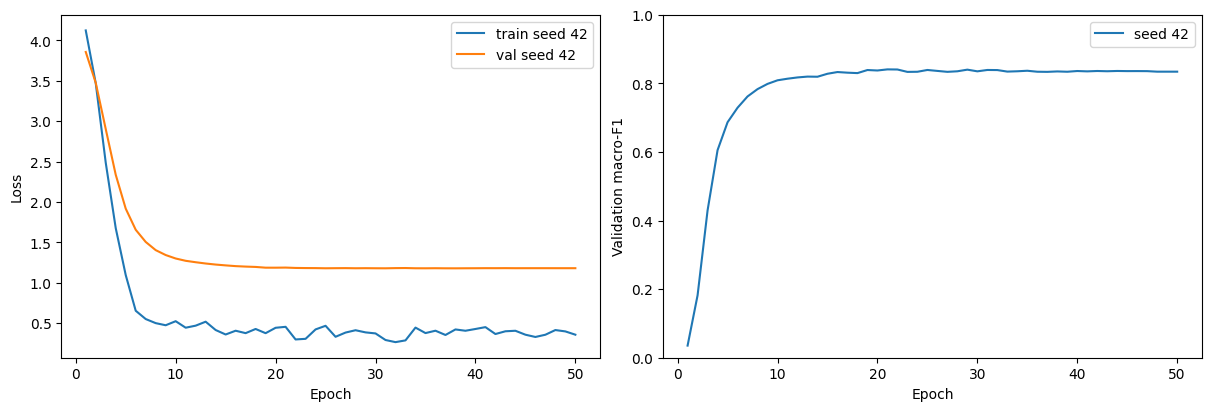

Saved results: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16/architecture_03_prefix_candidate_only_mltm_alignment_results.csv
Saved report: /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16/architecture_03_prefix_candidate_only_mltm_alignment_report.md


,count,valid_captions,valid_rate,class_term_rate
split,,,,
train,376,324,0.861702,0.138298


,intervention,split,query_count,shuffle_testable,accuracy,macro_f1,loss,candidate_caption_available_rate,candidate_caption_rate,mean_query_gate,...,mean_abs_probability_change,mean_kl_from_aligned,delta_macro_f1,changed_prediction_rate,ci95_low,ci95_high,experiment,seed,best_epoch,study_stage
0,aligned,val,1880,True,0.836170,0.834947,1.178478,0.82234,0.82234,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment
1,text_off,val,1880,True,0.836170,0.835391,1.191238,0.82234,0.00000,0.0,...,0.001562,0.011309,0.000444,0.014894,-0.003847,0.004852,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment
2,text_shuffled,val,1880,True,0.838298,0.837773,1.193158,0.82234,0.82234,0.0,...,0.001777,0.014584,0.002826,0.017021,-0.001256,0.007914,candidate_only,42,38,03_prefix_candidate_only_mltm_alignment


,scope,alignment_enabled,eligible_pairs,unique_captions,transport_kl,positive_mass,marginal_error,mean_pair_cosine,caption_group_top1,exact_source_top1,metric_diagonal_min,metric_diagonal_max,metric_condition_ratio,experiment,seed,best_epoch
0,training_pool_fit_not_held_out_retrieval,True,324,289,2.656227,0.093364,0.000001,0.429815,0.746914,0.67284,0.846199,1.126969,1.331802,candidate_only,42,38


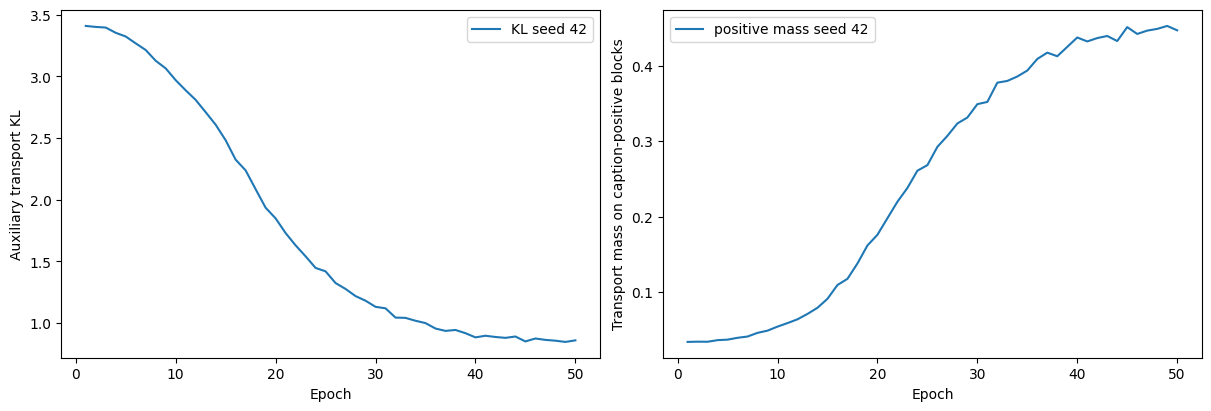

In [19]:
validation_summary = summarize_ablation("val")
test_summary = summarize_ablation("test") if RUN_FINAL_TEST else pd.DataFrame()
status = ablation_run_status()
display(status)
result_tables = [frame.assign(split=name) for name, frame in (("val", validation_summary), ("test", test_summary))
                 if not frame.empty]
results = pd.concat(result_tables, ignore_index=True) if result_tables else pd.DataFrame(
    columns=["experiment", "seed", "split", "epochs_trained", "best_epoch", "accuracy", "macro_f1", "loss"])
results = results.assign(study_stage=ARCHITECTURE_STUDY["stage"], caption_method=CAPTION_BINDING["method"],
    caption_csv_sha256=CAPTION_BINDING["sha256"], query_text_enabled=False,
    candidate_text_enabled=True, norm_calibrated_fusion=True, semantic_selector_enabled=False, alignment_enabled=ALIGNMENT_WEIGHT > 0, alignment_method="mltm_inspired_image_caption_v1",
    token_fusion_enabled=False, aswp_enabled=False)
results.to_csv(OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_results.csv", index=False)
display(results.round(4))


def markdown_table(frame):
    if frame.empty:
        return "No completed metrics yet."
    columns = list(frame.columns)
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines += ["| " + " | ".join(str(value).replace("|", "/") for value in row) + " |"
              for row in frame.round(5).fillna("").itertuples(index=False, name=None)]
    return "\n".join(lines)


report = [f"# DTD split {DTD_SPLIT}: architecture study 03 / Florence-Prefix / candidate_only + norm fusion + auxiliary alignment", "",
          f"Epoch budget: {EPOCHS}; LR schedule horizon: {LR_SCHEDULE_EPOCHS}; early stopping: {EARLY_STOPPING}.",
          "Query image + one context image + its screened caption. Query text and semantic selector are disabled.",
          "Candidate-only with L2-normalized projected candidate text; the exact Prefix CSV is frozen.", "",
          "## Run status", "", markdown_table(status), "", "## Metrics", "", markdown_table(results), "",
          "Candidate pool contains training images only; self-selection is excluded.",
          "Query gate is always zero; candidate gate is learned for valid selected captions. The caption policy is recorded in the protocol.",
          "Auxiliary image-caption alignment with a positive diagonal Mahalanobis metric; no Partial OT, semantic selector, token fusion or ASWP.",
          "Keep split, pool seed, training seed, preprocessing, budget and LR horizon fixed in later notebooks.",
          "Use validation for development; do not select later variants by repeated test-score tuning."]
(OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").write_text("\n".join(report) + "\n", encoding="utf-8")

histories = []
for seed in TRAIN_SEEDS:
    path = RUNS_DIR / "candidate_only" / f"seed_{seed}" / "history.csv"
    if path.is_file():
        try:
            history = pd.read_csv(path)
        except pd.errors.EmptyDataError:
            continue
        if not history.empty:
            histories.append((seed, history))
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for seed, history in histories:
        axes[0].plot(history.epoch, history.train_loss, label=f"train seed {seed}")
        axes[0].plot(history.epoch, history.val_loss, label=f"val seed {seed}")
        axes[1].plot(history.epoch, history.val_macro_f1, label=f"seed {seed}")
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Validation macro-F1")
    axes[1].set_ylim(0, 1)
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.legend()
    fig.savefig(OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_training.png", dpi=160, bbox_inches="tight")
    plt.show()
print("Saved results:", OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_results.csv")
print("Saved report:", OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md")

if "audit_summary" in globals():
    display(audit_summary)
    with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
        handle.write("\n## Candidate-pool caption coverage\n\n" + markdown_table(audit_summary.reset_index()) + "\n")

with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
    handle.write(f"\nCaption input policy: {CAPTION_INPUT_POLICY}. Semantic scores are diagnostic-only for dtd_lexical_v2. Policy changes define different experiments; do not mix their protocols.\n")

with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
    handle.write("\n## Caption provenance\n\n" + json.dumps(CAPTION_BINDING, indent=2) + "\n")
    handle.write("\nThese captions are synthetic model inputs, not human-verified ground truth. "
                 "Historical F1 values, including study01 F1 0.853032, are not metrics of this model.\n")

diagnostic_path = OUT_PUT_DIR / "validation_interventions.csv"
if diagnostic_path.is_file():
    validation_diagnostics = pd.read_csv(diagnostic_path)
    display(validation_diagnostics.round(6))
    with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
        handle.write("\n## Fixed-context validation text interventions\n\n" + markdown_table(validation_diagnostics) + "\n")
        handle.write("\nNorm/gate distributions and per-image interventions are in each run's validation_norm_diagnostics/ directory. "
                     "A small gate is not a percentage contribution; inspect weighted_text_visual_ratio. "
                     "Shuffled duplicate captions can remain text-identical; consult the shuffle assignment export.\n")

alignment_fit_tables = []
for seed in TRAIN_SEEDS:
    path = RUNS_DIR / "candidate_only" / f"seed_{seed}" / "validation_norm_diagnostics/training_pool_alignment_summary.csv"
    if path.is_file():
        alignment_fit_tables.append(pd.read_csv(path))
if alignment_fit_tables:
    alignment_fit = pd.concat(alignment_fit_tables, ignore_index=True)
    alignment_fit.to_csv(OUT_PUT_DIR / "training_pool_alignment_summary.csv", index=False)
    display(alignment_fit.round(6))
    with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
        handle.write("\n## Training-pool alignment fit, not held-out retrieval\n\n" + markdown_table(alignment_fit) + "\n")
with (OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_report.md").open("a", encoding="utf-8") as handle:
    handle.write("\n## Auxiliary alignment configuration\n\n" + json.dumps(alignment_protocol_config(), indent=2) + "\n")
    handle.write("\nCompare study03 against study02 under the same protocol. Captions remain synthetic weak pairs, not verified ground truth. "
                 "m-LTM-inspired adaptation: https://arxiv.org/abs/2405.10084 . No faithful audio-text reproduction is claimed.\n")
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for seed, history in histories:
        axes[0].plot(history.epoch, history.train_alignment_loss, label=f"KL seed {seed}")
        axes[1].plot(history.epoch, history.train_alignment_positive_mass, label=f"positive mass seed {seed}")
    axes[0].set_ylabel("Auxiliary transport KL")
    axes[1].set_ylabel("Transport mass on caption-positive blocks")
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.legend()
    fig.savefig(OUT_PUT_DIR / "architecture_03_prefix_candidate_only_mltm_alignment_alignment_training.png", dpi=160, bbox_inches="tight")
    plt.show()


In [20]:
import csv
from datetime import datetime
import io
import json
from pathlib import Path
import shutil
import zipfile

# ==============================================================================
# 1. CẤU HÌNH ĐÓNG GÓI (CHỈNH SỬA TẠI ĐÂY NẾU CẦN)
# ==============================================================================
STUDY_DIRECTORIES = {
    "study02_norm_fusion": Path(
        "/kaggle/working/outputs/mtacs_dtd_split1_architecture_02_prefix_candidate_only_norm_fusion_vitl16"
    ),
    "study03_mltm_alignment": Path(
        "/kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16"
    ),
}

# Đặt True nếu muốn đóng gói thêm last.pt để phục vụ resume sau này
INCLUDE_LAST_CHECKPOINT = False

# Thêm đường dẫn file .ipynb đã lưu trên đĩa (nếu có), ví dụ: ["/kaggle/working/my_notebook.ipynb"]
NOTEBOOK_PATHS = []

# Thư mục xuất file ZIP và tiền tố tên file
OUTPUT_DIR = Path("/kaggle/working")
ZIP_PREFIX = "dtd_study02_study03_results"

# Các định dạng văn bản, log, dữ liệu bảng và biểu đồ được phép thu thập
ALLOWED_DOC_EXTENSIONS = {".csv", ".json", ".md", ".txt", ".log", ".png"}
ALLOWED_CHECKPOINTS = (
    {"best.pt", "last.pt"} if INCLUDE_LAST_CHECKPOINT else {"best.pt"}
)

# Các tên file/thư mục trung gian, cache hoặc trọng số pretrained cần loại trừ tuyệt đối
EXCLUDED_DIR_NAMES = {
    "__pycache__",
    ".ipynb_checkpoints",
    ".git",
    "images",
    "dinov3",
    "clip",
    "florence",
}
EXCLUDED_FILE_KEYWORDS = (
    "candidate_text_embeddings",
    "feature_bank",
    "image_bank",
    "embedding_cache",
)
EXCLUDED_TEMP_SUFFIXES = (".tmp", ".part", ".bak", ".swp", ".zip", ".tar", ".gz")
STREAM_CHUNK_BYTES = 8 * 1024 * 1024  # Đọc theo luồng 8MB, không nạp hết vào RAM


# ==============================================================================
# 2. HÀM KIỂM TRA & THU THẬP FILE
# ==============================================================================
def format_bytes(num_bytes: int) -> str:
  size = float(num_bytes)
  for unit in ("B", "KB", "MB", "GB", "TB"):
    if size < 1024.0 or unit == "TB":
      return f"{size:.2f} {unit}" if unit != "B" else f"{int(size)} B"
    size /= 1024.0
  return f"{num_bytes} B"


def is_valid_result_file(file_path: Path) -> tuple[bool, str]:
  """Kiểm tra file có thuộc danh sách cần lưu và không vi phạm quy tắc loại trừ."""
  name_lower = file_path.name.lower()
  suffix_lower = file_path.suffix.lower()

  # Loại trừ thư mục cấm trong đường dẫn
  for part in file_path.parts:
    if part.lower() in EXCLUDED_DIR_NAMES:
      return False, "excluded_directory"

  # Loại trừ file tạm hoặc file nén cũ
  if name_lower.endswith(EXCLUDED_TEMP_SUFFIXES) or name_lower.startswith("."):
    return False, "temp_or_archive"

  # Loại trừ cache embedding / bank trung gian
  if any(keyword in name_lower for keyword in EXCLUDED_FILE_KEYWORDS):
    return False, "intermediate_cache_or_bank"

  # Kiểm tra file checkpoint (.pt / .pth)
  if suffix_lower in {".pt", ".pth", ".bin", ".safetensors", ".ckpt", ".npy", ".npz"}:
    if file_path.name in ALLOWED_CHECKPOINTS:
      return True, "checkpoint"
    return False, "disallowed_tensor_or_checkpoint"

  # Kiểm tra các định dạng kết quả, cấu hình, báo cáo và biểu đồ
  if suffix_lower in ALLOWED_DOC_EXTENSIONS:
    return True, "document_or_plot"

  return False, "unsupported_extension"


def audit_important_files(study_key: str, root_dir: Path, collected_rel_paths: set[str]) -> list[str]:
  """Kiểm tra sự tồn tại của các nhóm file quan trọng trong từng thí nghiệm."""
  missing = []
  if not root_dir.exists() or not root_dir.is_dir():
    return [f"Toàn bộ thư mục thí nghiệm không tồn tại: {root_dir}"]

  rel_names = {Path(p).name: p for p in collected_rel_paths}

  # Các file cấu hình và tổng hợp cốt lõi ở cấp độ thí nghiệm
  core_expected = [
    "protocol.json",
    "experiment_plan.json",
    "environment.json",
    "candidate_pool.csv",
    "validation_split.csv",
    "validation_interventions.csv",
    "shared/captions.csv",
    "shared/caption_source.json",
    "shared/candidate_caption_audit_summary.csv",
  ]
  for rel_item in core_expected:
    if rel_item not in collected_rel_paths:
      missing.append(f"{rel_item} (chưa có)")

  # Kiểm tra file kết quả tổng hợp (.csv) và báo cáo (.md) ở thư mục gốc của study
  if not any(p.endswith("_results.csv") and "/" not in p for p in collected_rel_paths):
    missing.append("*_results.csv (bảng tổng hợp kết quả cuối cùng)")
  if not any(p.endswith("_report.md") and "/" not in p for p in collected_rel_paths):
    missing.append("*_report.md (báo cáo tổng hợp Markdown)")

  # Kiểm tra các file trong nhánh runs/ (history, config, completed, best.pt, validation_norm_diagnostics)
  has_history = any(p.endswith("/history.csv") for p in collected_rel_paths)
  has_best_pt = any(p.endswith("/best.pt") for p in collected_rel_paths)
  has_completed = any(p.endswith("/completed.json") for p in collected_rel_paths)
  has_val_diag = any("validation_norm_diagnostics/" in p for p in collected_rel_paths)

  if not has_history:
    missing.append("runs/.../history.csv (lịch sử huấn luyện)")
  if not has_best_pt:
    missing.append("runs/.../best.pt (checkpoint tốt nhất)")
  if not has_completed:
    missing.append("runs/.../completed.json (trạng thái hoàn tất huấn luyện)")
  if not has_val_diag:
    missing.append("runs/.../validation_norm_diagnostics/* (chẩn đoán validation)")

  if INCLUDE_LAST_CHECKPOINT and not any(p.endswith("/last.pt") for p in collected_rel_paths):
    missing.append("runs/.../last.pt (được yêu cầu qua INCLUDE_LAST_CHECKPOINT=True nhưng không tìm thấy)")

  # Yêu cầu riêng đối với Notebook 03 (MLTM Alignment)
  if study_key == "study03_mltm_alignment":
    study03_specific = [
      "alignment_config.json",
      "alignment_pair_manifest.csv",
      "training_pool_alignment_summary.csv",
    ]
    for req_name in study03_specific:
      if req_name not in rel_names:
        missing.append(f"{req_name} (file đặc thù của Study 03 MLTM Alignment)")

  return missing


def write_stream_to_zip(zf: zipfile.ZipFile, src_path: Path, arcname: str, is_checkpoint: bool) -> None:
  """Ghi file vào ZIP theo luồng (streaming), dùng ZIP_STORED cho checkpoint và ZIP_DEFLATED cho văn bản."""
  zinfo = zipfile.ZipInfo.from_file(src_path, arcname=arcname)
  zinfo.compress_type = zipfile.ZIP_STORED if is_checkpoint else zipfile.ZIP_DEFLATED
  if not is_checkpoint:
    zinfo._compresslevel = 6
  with src_path.open("rb") as src_stream, zf.open(zinfo, mode="w", force_zip64=True) as dst_stream:
    shutil.copyfileobj(src_stream, dst_stream, length=STREAM_CHUNK_BYTES)


# ==============================================================================
# 3. QUÉT DỮ LIỆU & KIỂM TRA TRƯỚC KHI ĐÓNG GÓI
# ==============================================================================
collected_items = []  # Mỗi phần tử: dict(experiment, src_path, arcname, size_bytes, category)
seen_arcnames = set()
missing_summary = {}
warnings_log = []

print("=" * 78)
print("BẮT ĐẦU QUÉT DỮ LIỆU KẾT QUẢ THÍ NGHIỆM DTD (STUDY 02 & STUDY 03)")
print("=" * 78)

for study_key, study_root in STUDY_DIRECTORIES.items():
  study_rel_paths = set()
  if not study_root.exists():
    msg = f"[CẢNH BÁO] Không tìm thấy thư mục của {study_key}: {study_root}"
    print(msg)
    warnings_log.append(msg)
    missing_summary[study_key] = [f"Thư mục gốc không tồn tại: {study_root}"]
    continue

  study_files_count = 0
  study_bytes = 0

  for item_path in sorted(study_root.rglob("*")):
    if not item_path.is_file() or item_path.is_symlink():
      continue

    allowed, category = is_valid_result_file(item_path)
    if not allowed:
      continue

    rel_path = item_path.relative_to(study_root).as_posix()
    arcname = f"{study_key}/{rel_path}"

    if arcname in seen_arcnames:
      warn_dup = f"[CẢNH BÁO] Bỏ qua đường dẫn trùng lặp trong ZIP: {arcname}"
      print(warn_dup)
      warnings_log.append(warn_dup)
      continue

    file_size = item_path.stat().st_size
    seen_arcnames.add(arcname)
    study_rel_paths.add(rel_path)
    collected_items.append({
        "experiment": study_key,
        "source_path": str(item_path.resolve()),
        "arcname": arcname,
        "size_bytes": file_size,
        "size_human": format_bytes(file_size),
        "category": category,
    })
    study_files_count += 1
    study_bytes += file_size

  print(f"-> {study_key}: thu thập {study_files_count} file ({format_bytes(study_bytes)}) từ {study_root}")

  # Đối chiếu các file quan trọng còn thiếu
  study_missing = audit_important_files(study_key, study_root, study_rel_paths)
  missing_summary[study_key] = study_missing
  if study_missing:
    print(f"   [CẢNH BÁO] {study_key} đang thiếu {len(study_missing)} mục quan trọng:")
    for m in study_missing:
      print(f"     - {m}")

# Kiểm tra danh sách NOTEBOOK_PATHS do người dùng cấu hình
missing_notebooks = []
if NOTEBOOK_PATHS:
  for idx, nb_raw in enumerate(NOTEBOOK_PATHS, start=1):
    nb_path = Path(nb_raw).expanduser()
    if nb_path.is_file() and nb_path.suffix.lower() == ".ipynb":
      arcname = f"notebooks/{nb_path.name}"
      if arcname in seen_arcnames:
        arcname = f"notebooks/{idx:02d}_{nb_path.name}"
      seen_arcnames.add(arcname)
      fsize = nb_path.stat().st_size
      collected_items.append({
          "experiment": "notebooks",
          "source_path": str(nb_path.resolve()),
          "arcname": arcname,
          "size_bytes": fsize,
          "size_human": format_bytes(fsize),
          "category": "notebook",
      })
      print(f"-> Đã thêm notebook: {nb_path} -> {arcname} ({format_bytes(fsize)})")
    else:
      warn_nb = f"[CẢNH BÁO] Không tìm thấy file notebook hợp lệ tại: {nb_raw}"
      print(warn_nb)
      warnings_log.append(warn_nb)
      missing_notebooks.append(str(nb_raw))
else:
  print(
      "\n[LƯU Ý VỀ NOTEBOOK] Biến NOTEBOOK_PATHS đang để trống ([]).\n"
      "  Script không tự tạo/giả lập xuất notebook đang chạy trên trình duyệt.\n"
      "  Để lưu lại code kèm toàn bộ output hiển thị, bạn hãy chọn 'File -> Download Notebook'\n"
      "  hoặc bấm 'Save Version' trực tiếp trên giao diện Kaggle Editor."
  )

if missing_notebooks:
  missing_summary["notebooks"] = [f"Không tìm thấy: {p}" for p in missing_notebooks]

# Dừng ngay nếu không có bất kỳ file hợp lệ nào để tránh tạo ZIP rỗng
if not collected_items:
  raise RuntimeError(
      "DỪNG ĐÓNG GÓI: Không tìm thấy bất kỳ file kết quả hợp lệ nào trong cả hai thư mục thí nghiệm "
      "cũng như NOTEBOOK_PATHS. Không có file ZIP nào được tạo."
  )


# ==============================================================================
# 4. ĐÓNG GÓI STREAMING VÀO FILE ZIP & TẠO MANIFEST
# ==============================================================================
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
zip_filename = f"{ZIP_PREFIX}_{timestamp}.zip"
zip_filepath = OUTPUT_DIR / zip_filename

print("\n" + "=" * 78)
print(f"ĐANG ĐÓNG GÓI VÀO: {zip_filepath}")
print("=" * 78)

with zipfile.ZipFile(zip_filepath, mode="w", compression=zipfile.ZIP_DEFLATED, allowZip64=True) as zf:
  # Ghi từng file theo luồng
  for item in collected_items:
    src = Path(item["source_path"])
    is_ckpt = item["category"] == "checkpoint"
    write_stream_to_zip(zf, src, item["arcname"], is_checkpoint=is_ckpt)

  # Tạo package_manifest.csv ngay trong ZIP
  csv_buffer = io.StringIO()
  csv_writer = csv.DictWriter(
      csv_buffer,
      fieldnames=["experiment", "source_path", "arcname", "size_bytes", "size_human", "category"],
  )
  csv_writer.writeheader()
  csv_writer.writerows(collected_items)
  zf.writestr("package_manifest.csv", csv_buffer.getvalue().encode("utf-8"))

  # Tạo package_manifest.json (kèm thống kê tổng quan và danh sách file thiếu)
  total_raw_bytes = sum(x["size_bytes"] for x in collected_items)
  manifest_payload = {
      "created_at_utc": datetime.utcnow().strftime("%Y-%m-%dT%H:%M:%SZ"),
      "zip_filename": zip_filename,
      "include_last_checkpoint": INCLUDE_LAST_CHECKPOINT,
      "total_collected_files": len(collected_items),
      "total_uncompressed_bytes": total_raw_bytes,
      "total_uncompressed_human": format_bytes(total_raw_bytes),
      "study_directories": {k: str(v) for k, v in STUDY_DIRECTORIES.items()},
      "missing_important_files": missing_summary,
      "warnings": warnings_log,
      "files": collected_items,
  }
  zf.writestr(
      "package_manifest.json",
      json.dumps(manifest_payload, indent=2, ensure_ascii=False).encode("utf-8"),
  )

  # Tạo bản tóm tắt dễ đọc về các file quan trọng còn thiếu (missing_files_summary.txt)
  summary_lines = [
      f"BÁO CÁO KIỂM TRA FILE QUAN TRỌNG ({timestamp})",
      "=" * 60,
      f"Tổng số file đã đóng gói : {len(collected_items)}",
      f"Tổng dung lượng gốc      : {format_bytes(total_raw_bytes)}",
      f"Lấy thêm last.pt         : {INCLUDE_LAST_CHECKPOINT}",
      "",
  ]
  for st_key, st_missing in missing_summary.items():
    summary_lines.append(f"[{st_key}]")
    if not st_missing:
      summary_lines.append("  - Đầy đủ tất cả các file quan trọng.")
    else:
      for m_item in st_missing:
        summary_lines.append(f"  - THIẾU: {m_item}")
    summary_lines.append("")

  zf.writestr("missing_files_summary.txt", "\n".join(summary_lines).encode("utf-8"))


# ==============================================================================
# 5. KIỂM TRA TÍNH TOÀN VẸN & HIỂN THỊ LIÊN KẾT TẢI VỀ
# ==============================================================================
with zipfile.ZipFile(zip_filepath, mode="r") as zf_check:
  corrupted_entry = zf_check.testzip()
  if corrupted_entry is not None:
    raise RuntimeError(f"LỖI TOÀN VẸN ZIP: File '{corrupted_entry}' bên trong ZIP bị hỏng!")
  total_entries_in_zip = len(zf_check.infolist())

zip_size_bytes = zip_filepath.stat().st_size
raw_size_bytes = sum(x["size_bytes"] for x in collected_items)

print("KIỂM TRA TOÀN VẸN ZIP: THÀNH CÔNG (OK)")
print(f"  - Đường dẫn file ZIP    : {zip_filepath}")
print(f"  - Số file kết quả thu thập: {len(collected_items)} file (+ 3 file manifest trong ZIP = {total_entries_in_zip} mục)")
print(f"  - Tổng dung lượng gốc   : {format_bytes(raw_size_bytes)} ({raw_size_bytes:,} bytes)")
print(f"  - Dung lượng file ZIP   : {format_bytes(zip_size_bytes)} ({zip_size_bytes:,} bytes)")
print(
    "\n[HƯỚNG DẪN TẢI VỀ]\n"
    "  1. Nhấn trực tiếp vào liên kết bên dưới (nếu trình duyệt/Kaggle hỗ trợ).\n"
    "  2. Hoặc mở thanh bên phải của Kaggle -> mục 'Output' (/kaggle/working) -> nhấn biểu tượng\n"
    f"     Refresh và chọn tải file '{zip_filename}'."
)

try:
  from IPython.display import FileLink, display

  display(FileLink(str(zip_filepath.relative_to(Path.cwd()))))
except Exception:
  pass

BẮT ĐẦU QUÉT DỮ LIỆU KẾT QUẢ THÍ NGHIỆM DTD (STUDY 02 & STUDY 03)
[CẢNH BÁO] Không tìm thấy thư mục của study02_norm_fusion: /kaggle/working/outputs/mtacs_dtd_split1_architecture_02_prefix_candidate_only_norm_fusion_vitl16
-> study03_mltm_alignment: thu thập 47 file (1.19 GB) từ /kaggle/working/outputs/mtacs_dtd_split1_architecture_03_prefix_candidate_only_mltm_alignment_vitl16

[LƯU Ý VỀ NOTEBOOK] Biến NOTEBOOK_PATHS đang để trống ([]).
  Script không tự tạo/giả lập xuất notebook đang chạy trên trình duyệt.
  Để lưu lại code kèm toàn bộ output hiển thị, bạn hãy chọn 'File -> Download Notebook'
  hoặc bấm 'Save Version' trực tiếp trên giao diện Kaggle Editor.

ĐANG ĐÓNG GÓI VÀO: /kaggle/working/dtd_study02_study03_results_20261026_050358.zip


/tmp/ipykernel_91/3093815662.py:313: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at_utc": datetime.utcnow().strftime("%Y-%m-%dT%H:%M:%SZ"),


KIỂM TRA TOÀN VẸN ZIP: THÀNH CÔNG (OK)
  - Đường dẫn file ZIP    : /kaggle/working/dtd_study02_study03_results_20261026_050358.zip
  - Số file kết quả thu thập: 47 file (+ 3 file manifest trong ZIP = 50 mục)
  - Tổng dung lượng gốc   : 1.19 GB (1,275,739,168 bytes)
  - Dung lượng file ZIP   : 1.18 GB (1,269,462,125 bytes)

[HƯỚNG DẪN TẢI VỀ]
  1. Nhấn trực tiếp vào liên kết bên dưới (nếu trình duyệt/Kaggle hỗ trợ).
  2. Hoặc mở thanh bên phải của Kaggle -> mục 'Output' (/kaggle/working) -> nhấn biểu tượng
     Refresh và chọn tải file 'dtd_study02_study03_results_20261026_050358.zip'.


/kaggle/working/dtd_study02_study03_results_20261026_050358.zip